# CVID — EDA toàn bộ train / validation / test
Quét trực tiếp ZIP đã khóa hash; không chạy OCR, không sửa GT và không khóa cohort test.
Bao phủ toàn bộ frame, object XML và crop; các review trực quan được kiểm tra identity/hash trước khi hiển thị.
Test đã được quan sát trong EDA. Kết quả hỗ trợ đánh giá theo nhãn phát hành; không chứng nhận nhãn hoàn hảo, video/người viết độc lập hoặc test mù.

In [1]:
from pathlib import Path
import sys, json, itertools
import pandas as pd
from IPython.display import display, Markdown, Image, HTML
options = [Path.cwd(), Path.cwd()/'benchmark', *Path.cwd().parents]
ROOT = next(p for p in options if (p/'experiments/scripts/cvid_eda_scan.py').is_file())
sys.path.insert(0,str(ROOT))
from experiments.scripts.cvid_eda_scan import scan
from experiments.scripts.cvid_eda_common import OUT, sha, validate_artifacts, normalize_text
from experiments.scripts.cvid_eda_plots import *
from experiments.scripts.cvid_eda_notebook_support import table, figure, gallery, video_metadata, verify_reviews, finish
pd.set_option('display.max_colwidth',None)
snapshot = {p.relative_to(ROOT).as_posix():sha(p) for p in (ROOT/'experiments/registry/datasets').glob('iiit-cvid-spotting-*.json')}
print('Existing spotting artifacts bound:',len(snapshot),'| No model inference/imports or dependency installation')

Matplotlib is building the font cache; this may take a moment.


Existing spotting artifacts bound: 5 | No model inference/imports or dependency installation


## 1. Thu thập và đối chiếu toàn bộ nguồn
Cell sau thực sự giải mã toàn bộ frame/crop và đọc mọi XML. Hash pixel RGB + kích thước + nhãn tương thích được đối chiếu trong từng source group, có kiểm tra multiplicity.
Nhãn XML giữ nguyên. Thay `/` thành `-` chỉ là phép đối chiếu với crop index, không phải normalization của spotting.

In [2]:
receipt = scan()
validate_artifacts(receipt)
assert (receipt['frames'],receipt['objects'],receipt['decoded_crops']) == (5475,137745,137745)
assert receipt['read_failures']==receipt['unmatched_objects']==0
print(json.dumps({k:v for k,v in receipt.items() if k not in ('artifacts','scripts')},indent=2))
data = load_tables()
f,o,c,meta = [data[k] for k in ('frames','objects','crops','courses')]
assert len(c)==c.crop_id.nunique() and len(o)==o.object_id.nunique()
assert c.assigned_object_id.nunique()==len(o)
from experiments.scripts.cvid_eda_galleries import prepare_galleries
gallery_receipt = prepare_galleries()

Frames decoded: 1000


Frames decoded: 2000


Frames decoded: 3000


Frames decoded: 4000


Frames decoded: 5000


Crops decoded: 82263 after train


Crops decoded: 97642 after val


Crops decoded: 137745 after test


{
  "schema": "cvid_all_split_eda_scan_v1",
  "observed_at_utc": "2026-10-14T09:16:19.788619+00:00",
  "source_archive_sha256": "b5b562580e250ee3336462b7699bc79d0d1149d3b8cc82f1b221a0d0ce4fb489",
  "frames": 5475,
  "objects": 137745,
  "decoded_crops": 137745,
  "indexed_crops": 137745,
  "read_failures": 0,
  "unmatched_objects": 0,
  "crop_correspondence": {
    "unique": 137641,
    "equivalent_ambiguous": 104
  },
  "raw_crop_xml_label_differences": 238,
  "wall_seconds": 341.07296850000057,
  "runtime": {
    "python": "3.11.1",
    "packages": {
      "numpy": "2.4.6",
      "pandas": "3.0.5",
      "Pillow": "12.3.0"
    }
  },
  "inference_executed": false,
  "cohort_frozen": false
}


## 2. Accounting và thành phần split
ZIP và train index cùng có 3.171 frame train, trong khi paper ghi 3.170; không tự loại một frame để ép khớp paper.
Mỗi object là một annotation text/word do nguồn phát hành; không mặc định là một dòng chữ hay một mẫu độc lập.

**split-accounting: 3 rows exported; 3 shown.**

split,frames,xml_objects,nonblank_gt,decoded_crops,courses,folder_video_groups
train,3171,82263,82263,82263,12,395
val,549,15379,15379,15379,5,140
test,1755,40103,40103,40103,7,276


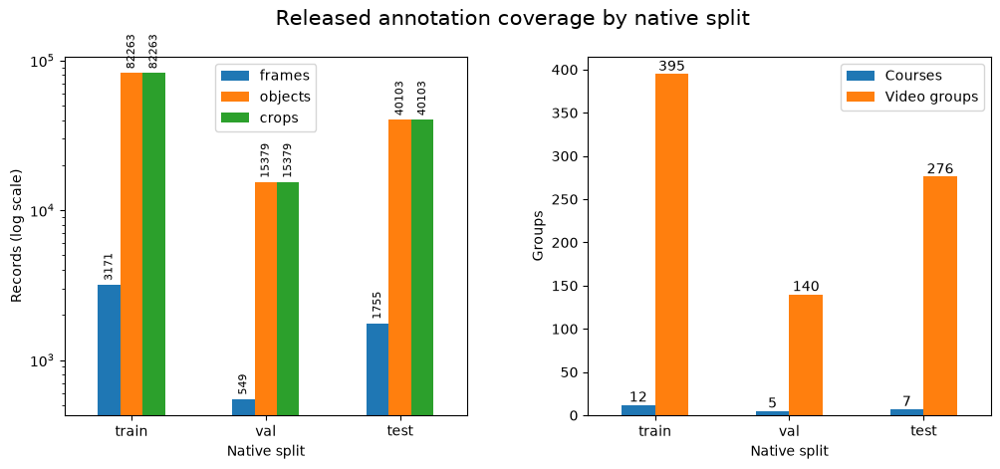

In [3]:
counts = pd.DataFrame({'frames':f.groupby('split').size(),'xml_objects':o.groupby('split').size(),
    'nonblank_gt':o.groupby('split').transcription_nonblank.sum(),'decoded_crops':c.groupby('split').size(),
    'courses':f.groupby('split').course.nunique(),'folder_video_groups':f.groupby('split').source_group.nunique()}).reindex(SPLITS).reset_index()
table(counts,'split-accounting')
figure(plot_counts(data),'01-accounting')

**all-course-metadata: 24 rows exported; 24 shown.**

split,course,CourseName,Field,Instructor,Medium,Specialization,VideoURL
test,10,Computer Organization,Engineering,Prof. S. Raman,Blackboard,Computer Systems,http://nptel.ac.in/courses/106106092/
test,14,Design and Analysis of Algorithms,Engineering,Various Professors of IIT Bombay,Paper,Data Structures and Algorithms,http://nptel.ac.in/courses/106101060/
test,18,Neural Network and Applications,Engineering,Prof. S Sengupta,Paper,Machine Learning,http://nptel.ac.in/courses/117105084/
test,20,Introduction to Computer Networks,Engineering,Prof. David Wetherall,Slides,Networking,https://www.coursera.org/course/comnetworks
test,24,Optoelectronic Material and Devices,Engineering,Prof. Dr. Deepak Gupta,WhiteBoard,Metallurgy,http://nptel.ac.in/courses/117104074/
test,3,Quantum Physics I,Physics,Various MIT Professors,Blackboard,Quantum Physics,https://www.youtube.com/watch?v=lZ3bPUKo5zc&index=1&list=PLYmwFR_XLSpbEjeyr6SsKMAbwRe0N6Qe3
test,7,Linear Algebra,Engineering,Prof. Gilbert Strang,Blackboard,Discrete Mathematics,https://ocw.mit.edu/courses/mathematics/18-06-linear-algebra-spring-2010/video-lectures/
train,1,Advanced Data Structures,Engineering,Prof. Erik Demaine,Blackboard,Data Structures and Algorithms,https://www.youtube.com/watch?v=T0yzrZL1py0&list=PLUl4u3cNGP61hsJNdULdudlRL493b-XZf
train,12,Introduction to Databases,Engineering,Prof. Jennifer Widom,Mixed,Databases,https://lagunita.stanford.edu/courses/Engineering/db/2014_1/courseware/
train,15,Digital Computer Organization,Engineering,Prof. P. K. Biswas,Paper,Electronics and Communications,http://nptel.ac.in/courses/117105078/


**course-concentration: 24 rows exported; 24 shown.**

split,course,medium,frames,objects,video_groups
test,10,Blackboard,224,2976,32
test,14,Paper,245,4910,31
test,18,Paper,282,5671,37
test,20,Slides,368,17097,89
test,24,WhiteBoard,244,5946,32
test,3,Blackboard,140,1261,22
test,7,Blackboard,252,2242,33
train,1,Blackboard,247,8128,21
train,12,Mixed,205,8623,54
train,15,Paper,102,2112,28


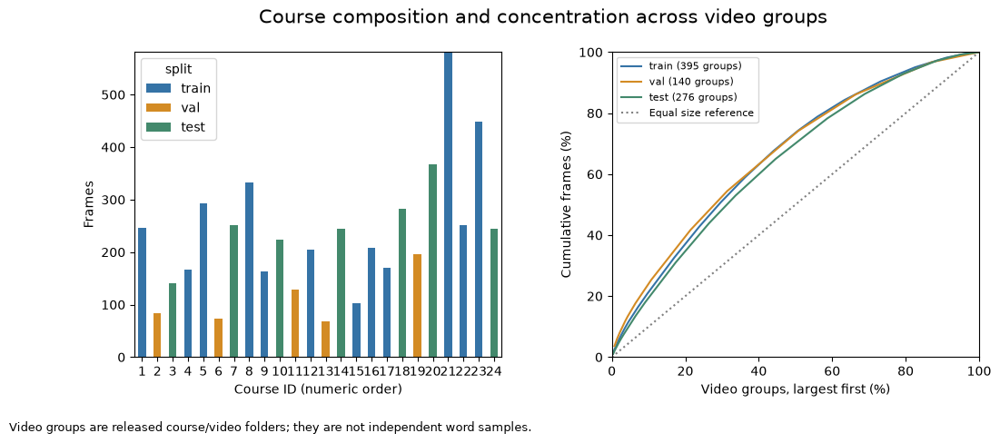

In [4]:
table(meta,'all-course-metadata')
course_counts = f.groupby(['split','course','medium']).agg(frames=('frame_id','size'),objects=('objects','sum'),video_groups=('source_group','nunique')).reset_index()
table(course_counts,'course-concentration')
figure(plot_courses(data),'02-courses-and-concentration')

**frame-distribution-summary: 3 rows exported; 3 shown.**

**all-video-group-counts: 811 rows exported; 18 shown.**

split,source_group,frames,objects
test,10/1,9,125
test,10/10,3,45
test,10/11,6,68
test,10/12,7,121
test,10/13,2,25
test,10/14,8,92
test,10/15,10,127
test,10/16,6,81
test,10/17,9,171
test,10/18,10,176


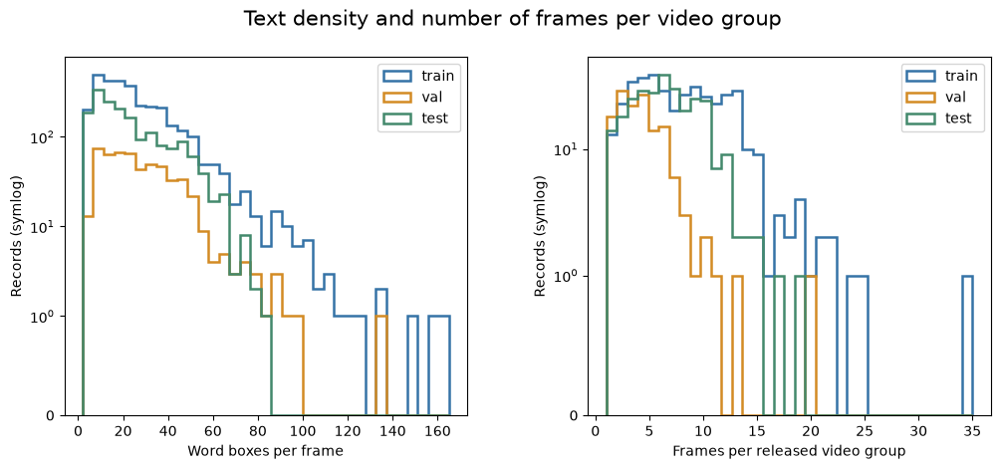

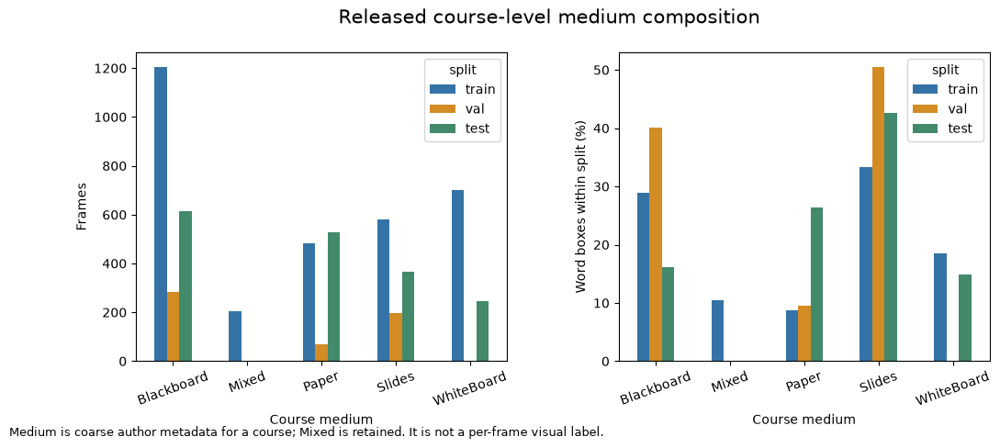

In [5]:
table(f.groupby('split')[['objects','width','height']].describe().round(2).reset_index(),'frame-distribution-summary')
table(f.groupby(['split','source_group']).agg(frames=('frame_id','size'),objects=('objects','sum')).reset_index(),'all-video-group-counts',preview=18)
figure(plot_density(data),'03-text-density')
figure(plot_modalities(data),'04-course-medium')

## 3. Độ phân giải, hình học và annotation bất thường
Medium là metadata cấp khóa học; `Mixed` giữ nguyên, không suy diễn thành nhãn từng frame.
KEEP/REPAIR/HOLD là kết quả kiểm tra cấu trúc, không chứng nhận transcription đúng về ngữ nghĩa.

**all-resolution-strata: 28 rows exported; 28 shown.**

split,width,height,frames
test,320,256,469
test,480,384,161
test,480,386,91
test,640,480,161
test,640,482,24
test,656,482,131
test,800,600,82
test,800,610,15
test,960,546,368
test,1280,720,17


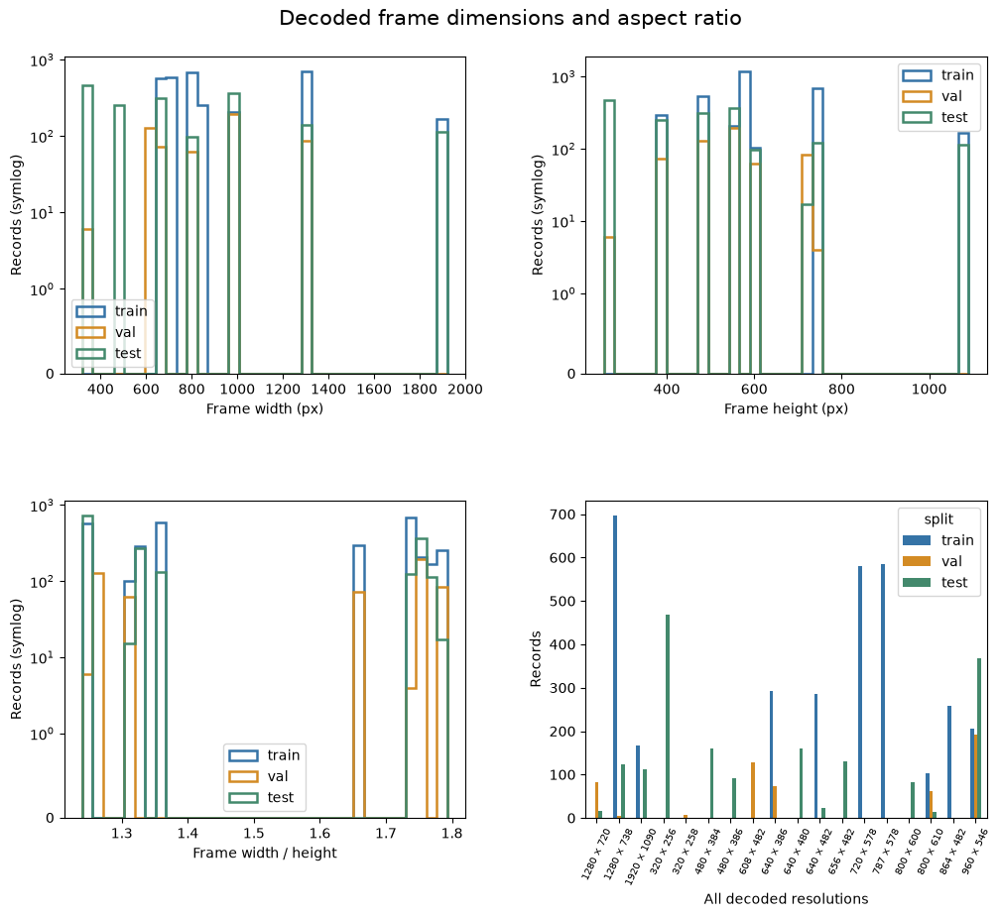

**frame-quality-decisions: 3 rows exported; 3 shown.**

decision,split,HOLD,KEEP,REPAIR_METADATA_DERIVED
,train,16,3135,20
,val,3,543,3
,test,1,1657,97


**all-invalid-boxes: 22 rows exported; 22 shown.**

object_id,text,xmin,ymin,xmax,ymax,frame_id
test/24/25/00_31_56_00006.png#object-0036,jle,-2,4,28,19,test/24/25/00_31_56_00006.png
train/1/1/01_13_20_00010.png#object-0008,tence,1174,222,1281,276,train/1/1/01_13_20_00010.png
train/1/1/01_13_20_00010.png#object-0031,irs,1206,280,1281,312,train/1/1/01_13_20_00010.png
train/1/15/00_57_10_00011.png#object-0039,rn,1256,160,1281,183,train/1/15/00_57_10_00011.png
train/1/17/00_32_39_00008.png#object-0021,n,1244,148,1281,185,train/1/17/00_32_39_00008.png
train/1/19/01_00_02_00008.png#object-0014,fessing,-1,319,120,353,train/1/19/01_00_02_00008.png
train/1/2/00_15_56_00005.png#object-0024,de,1228,364,1281,423,train/1/2/00_15_56_00005.png
train/1/20/00_57_38_00010.png#object-0028,b9,1256,109,1283,147,train/1/20/00_57_38_00010.png
train/1/21/01_14_52_00013.png#object-0028,tv,1232,45,1281,82,train/1/21/01_14_52_00013.png
train/1/6/00_26_59_00006.png#object-0040,seg,1232,303,1281,337,train/1/6/00_26_59_00006.png


**all-metadata-size-mismatches: 124 rows exported; 124 shown.**

frame_id,xml_width,xml_height,width,height,decision
test/10/23/00_04_57_00003.png,2,1,320,256,REPAIR_METADATA_DERIVED
test/10/25/00_45_38_00009.png,2,1,320,256,REPAIR_METADATA_DERIVED
test/18/10/00_30_26_00004.png,2,1,800,610,REPAIR_METADATA_DERIVED
test/18/35/00_22_18_00003.png,2,1,800,600,REPAIR_METADATA_DERIVED
test/20/62/00_01_35_00002.png,2,1,960,546,REPAIR_METADATA_DERIVED
test/20/62/00_13_26_00003.png,2,1,960,546,REPAIR_METADATA_DERIVED
test/20/63/00_01_55_00001.png,2,1,960,546,REPAIR_METADATA_DERIVED
test/20/63/00_03_08_00002.png,2,1,960,546,REPAIR_METADATA_DERIVED
test/20/63/00_07_27_00003.png,2,1,960,546,REPAIR_METADATA_DERIVED
test/20/63/00_12_37_00004.png,2,1,960,546,REPAIR_METADATA_DERIVED


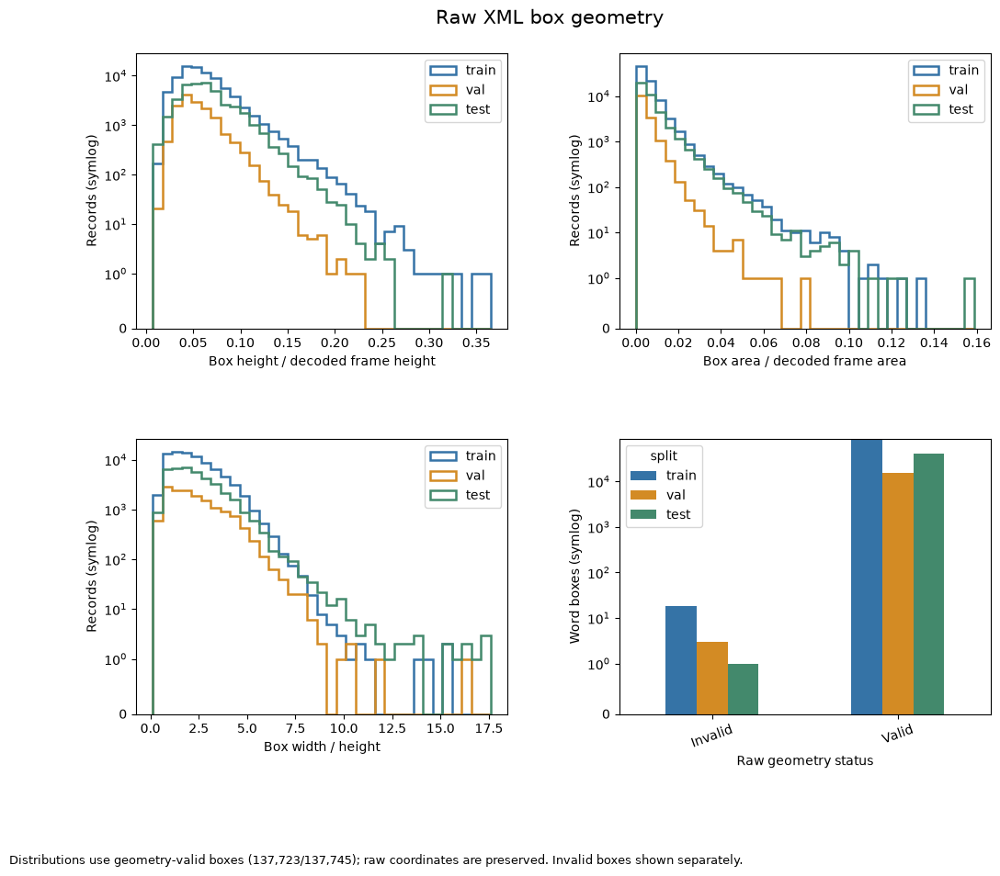

In [6]:
table(f.groupby(['split','width','height']).size().reset_index(name='frames'),'all-resolution-strata')
figure(plot_resolution(data),'05-frame-resolution')
decisions = pd.crosstab(f.split,f.decision).reindex(SPLITS).reset_index()
table(decisions,'frame-quality-decisions')
table(o[~o.geometry_valid][['object_id','text','xmin','ymin','xmax','ymax','frame_id']],'all-invalid-boxes')
table(f[f.xml_size_mismatch][['frame_id','xml_width','xml_height','width','height','decision']],'all-metadata-size-mismatches')
figure(plot_boxes(data),'06-box-geometry')

**geometry-contact-sheets/page-001.jpg**

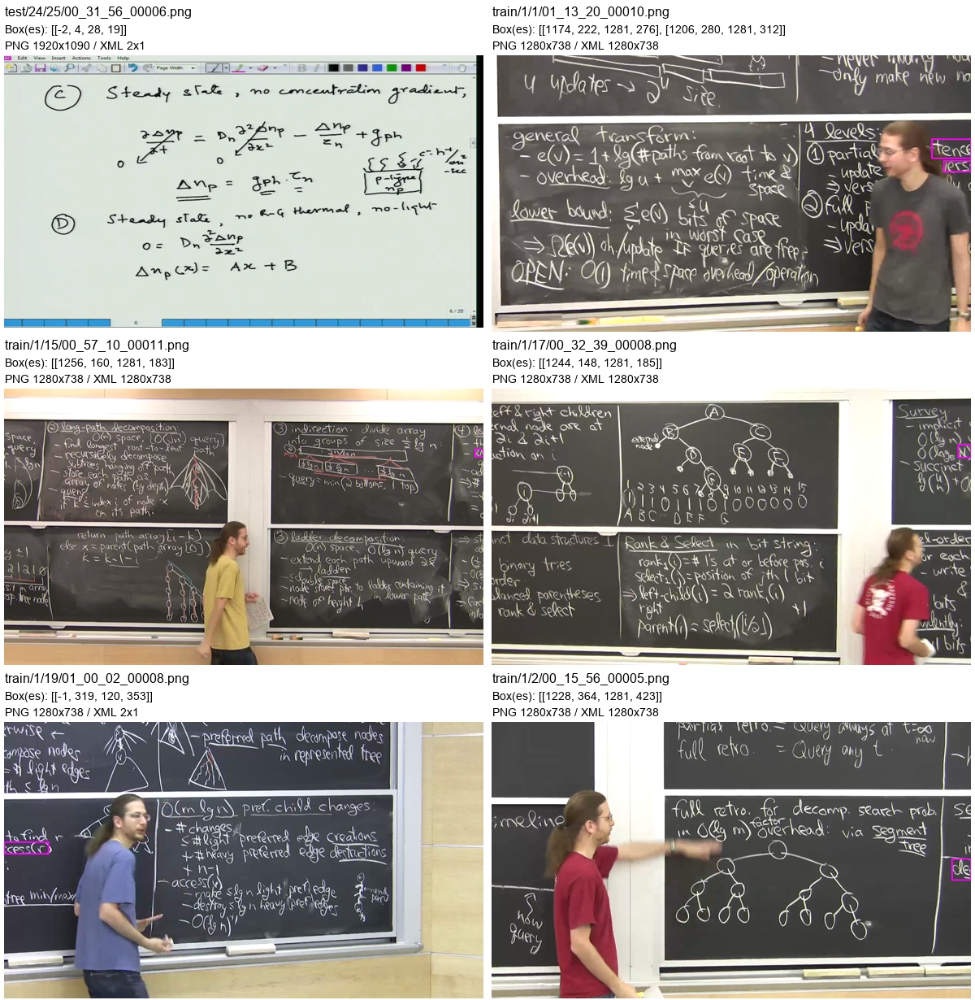

**geometry-contact-sheets/page-002.jpg**

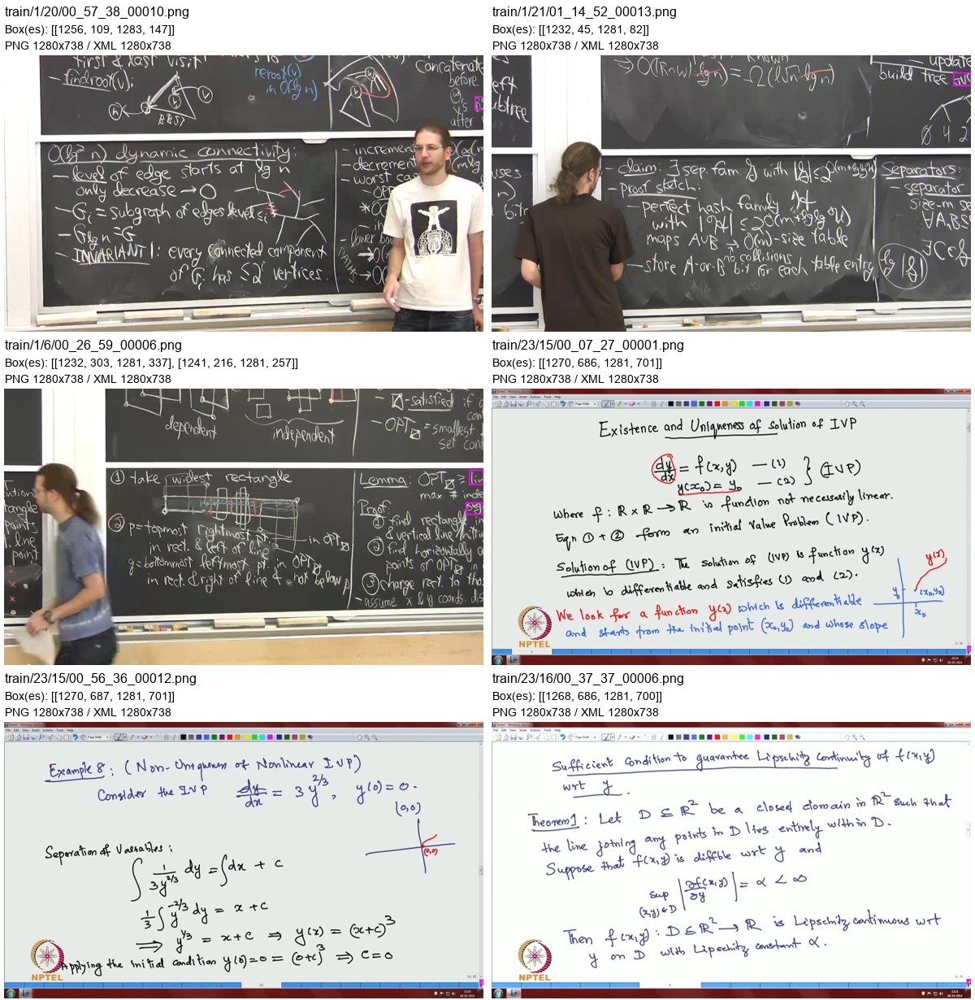

**geometry-contact-sheets/page-003.jpg**

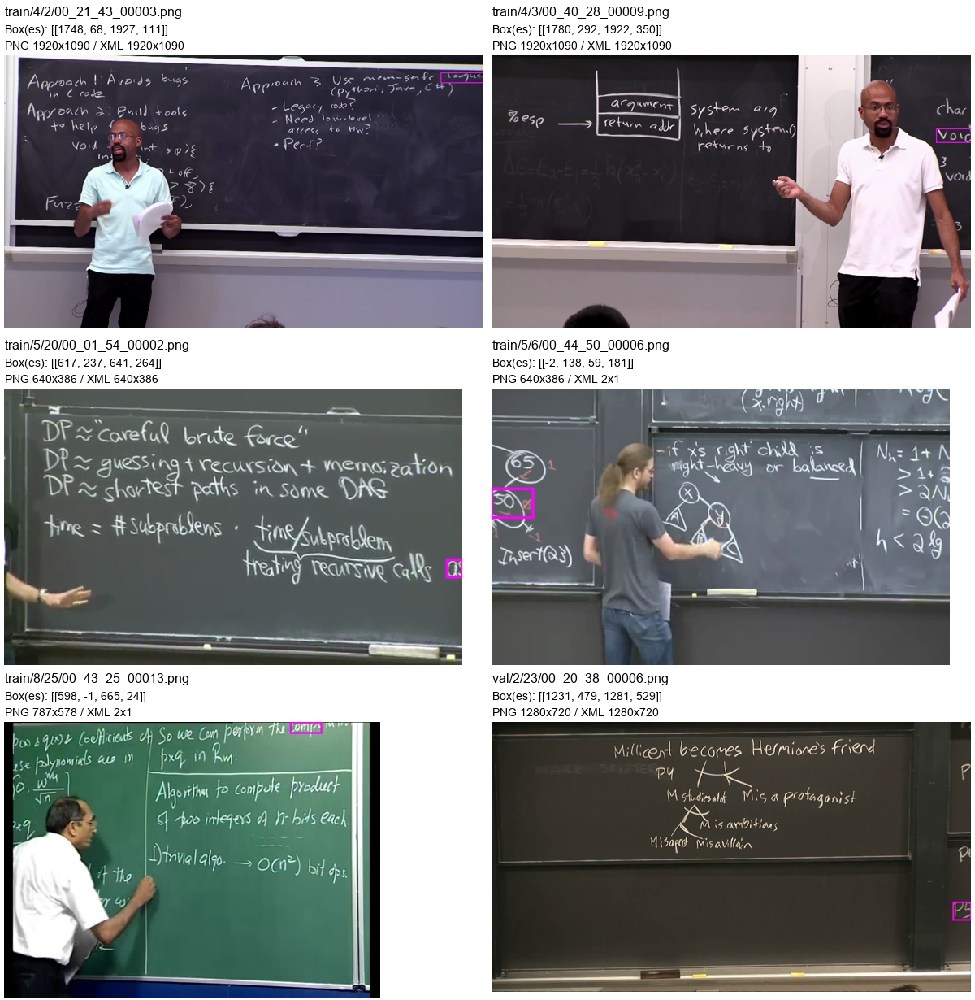

**geometry-contact-sheets/page-004.jpg**

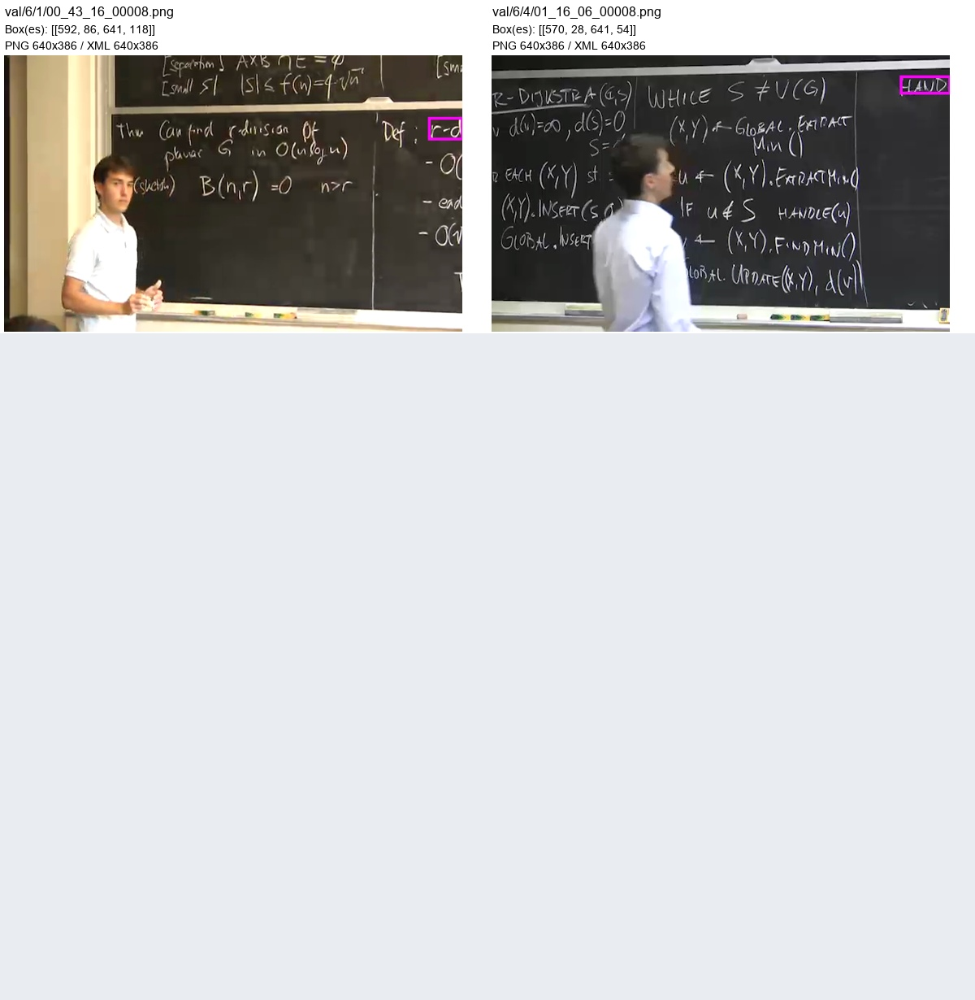

**mechanically-eligible-not-frozen: 3 rows exported; 3 shown.**

split,frames,objects
train,3155,81606
val,546,15317
test,1754,40063


Metadata repair chỉ dùng kích thước PNG trong derived records. Không clip box. Test còn 1.754 frame / 40.063 object về hình học; chưa khóa cohort.

In [7]:
gallery('geometry-contact-sheets')
eligible = f[f.decision!='HOLD'].groupby('split').agg(frames=('frame_id','size'),objects=('objects','sum')).reindex(SPLITS).reset_index()
table(eligible,'mechanically-eligible-not-frozen')
display(Markdown('Metadata repair chỉ dùng kích thước PNG trong derived records. Không clip box. Test còn 1.754 frame / 40.063 object về hình học; chưa khóa cohort.'))

## 4. Crop/frame correspondence và transcription
`unique` là đối ứng duy nhất theo pixel + nhãn trong source group. `equivalent_ambiguous` có nhiều object trùng pixel/nhãn: allocation chỉ phục vụ kiểm multiplicity, không chứng minh object ID mà tác giả định dùng.

**crop-correspondence-counts: 5 rows exported; 5 shown.**

split,correspondence,crops
test,equivalent_ambiguous,64
test,unique,40039
train,equivalent_ambiguous,40
train,unique,82223
val,unique,15379


**all-ambiguous-correspondence: 104 rows exported; 104 shown.**

crop_id,text,xml_text,equivalence_class_size,assigned_object_id,correspondence
Crops/train/12/2/1297.png,the,the,4,train/12/2/00_00_45_00001.png#object-0001,equivalent_ambiguous
Crops/train/12/2/1304.png,relational,relational,3,train/12/2/00_00_45_00001.png#object-0008,equivalent_ambiguous
Crops/train/12/2/1356.png,relational,relational,3,train/12/2/00_03_41_00002.png#object-0039,equivalent_ambiguous
Crops/train/12/2/1386.png,the,the,4,train/12/2/00_04_19_00003.png#object-0008,equivalent_ambiguous
Crops/train/12/2/1426.png,the,the,4,train/12/2/00_08_09_00004.png#object-0007,equivalent_ambiguous
Crops/train/12/2/1471.png,the,the,4,train/12/2/00_08_42_00005.png#object-0001,equivalent_ambiguous
Crops/train/12/2/1479.png,relational,relational,3,train/12/2/00_08_42_00005.png#object-0009,equivalent_ambiguous
Crops/train/12/33/3923.png,data,data,2,train/12/33/00_02_55_00002.png#object-0015,equivalent_ambiguous
Crops/train/12/33/3947.png,types,types,2,train/12/33/00_04_33_00003.png#object-0000,equivalent_ambiguous
Crops/train/12/33/3951.png,those,those,2,train/12/33/00_04_33_00003.png#object-0004,equivalent_ambiguous


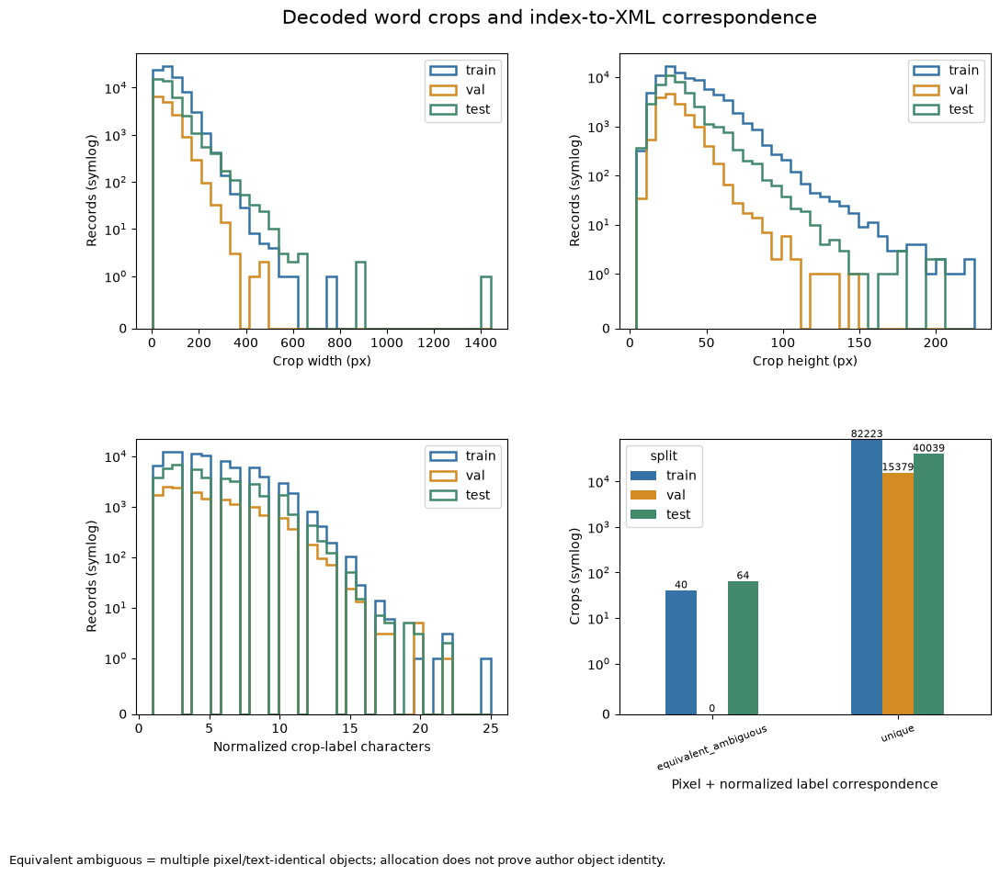

In [8]:
table(c.groupby(['split','correspondence']).size().reset_index(name='crops'),'crop-correspondence-counts')
table(c[c.correspondence!='unique'][['crop_id','text','xml_text','equivalence_class_size','assigned_object_id','correspondence']],'all-ambiguous-correspondence')
figure(plot_crops(data),'07-crop-resolution-and-correspondence')

**object-feature-summary: 3 rows exported; 3 shown.**

**longest-xml-label-examples: 24 rows exported; 24 shown.**

object_id,text,normalized_text,characters
train/21/14/00_52_19_00019.png#object-0031,(http://dbie.rbi.org.in/),(http://dbie.rbi.org.in/),25
test/20/82/00_10_47_00003.png#object-0037,counterrevolutionaries,counterrevolutionaries,22
test/20/88/00_00_31_00001.png#object-0019,electroencephalography,electroencephalography,22
train/1/16/00_20_21_00004.png#object-0005,trinaderepresenatation,trinaderepresenatation,22
train/12/33/00_10_43_00006.png#object-0025,counterrevolutionaries,counterrevolutionaries,22
train/12/33/00_12_31_00007.png#object-0019,counterrevolutionaries,counterrevolutionaries,22
val/6/2/00_57_01_00013.png#object-0015,(extract min(Q(R(G)))),(extract min(q(r(g)))),22
train/4/1/00_36_17_00004.png#object-0004,citi.com/acct?id=1234,citi.com/acct?id=1234,21
test/20/62/00_01_35_00002.png#object-0041,institutionalization,institutionalization,20
test/20/70/00_01_57_00001.png#object-0040,andrianampoinimerina,andrianampoinimerina,20


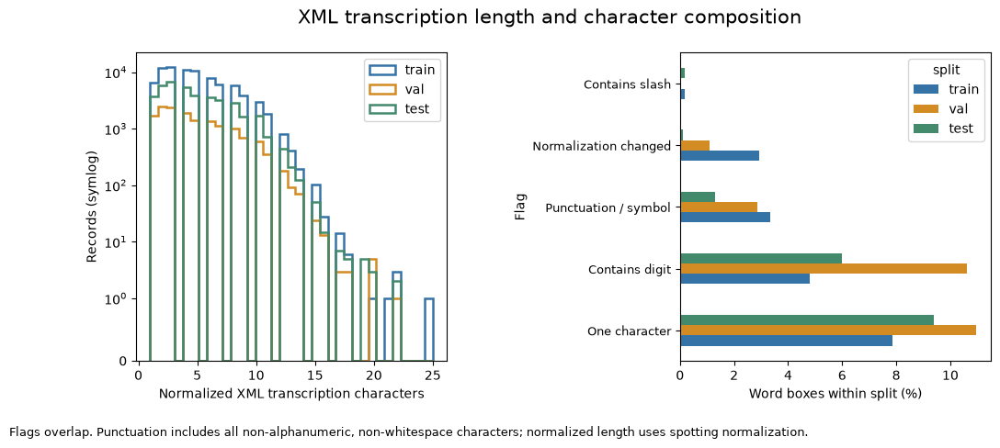

In [9]:
table(o.groupby('split')[['characters','box_height','box_height_rel','area_rel','aspect_ratio']].describe().round(4).reset_index(),'object-feature-summary')
table(o.sort_values(['characters','object_id'],ascending=[False,True])[['object_id','text','normalized_text','characters']].head(24),'longest-xml-label-examples')
figure(plot_text(data),'08-transcription-length-and-composition')

**all-238-crop-xml-label-differences: 238 rows exported; 238 shown.**

crop_id,assigned_object_id,xml_text,text,xml_normalized,crop_normalized,slash_rewrite_explains
Crops/train/1/13/1778.png,train/1/13/00_42_13_00009.png#object-0014,a/k,a-k,a/k,a-k,True
Crops/train/1/17/3171.png,train/1/17/00_19_44_00005.png#object-0032,ind/del,ind-del,ind/del,ind-del,True
Crops/train/1/17/3198.png,train/1/17/00_22_53_00006.png#object-0013,0/1,0-1,0/1,0-1,True
Crops/train/1/17/3210.png,train/1/17/00_22_53_00006.png#object-0025,0/1,0-1,0/1,0-1,True
Crops/train/1/17/3359.png,train/1/17/00_37_09_00009.png#object-0044,0/1,0-1,0/1,0-1,True
Crops/train/1/18/3515.png,train/1/18/00_32_20_00005.png#object-0036,1/2,1-2,1/2,1-2,True
Crops/train/1/21/5402.png,train/1/21/00_30_48_00007.png#object-0053,l/2,l-2,l/2,l-2,True
Crops/train/1/21/5413.png,train/1/21/00_30_48_00007.png#object-0064,l/g,l-g,l/g,l-g,True
Crops/train/1/21/5461.png,train/1/21/00_43_14_00008.png#object-0043,l/2,l-2,l/2,l-2,True
Crops/train/1/7/7197.png,train/1/7/00_03_26_00002.png#object-0008,i/o,i-o,i/o,i-o,True


**transcription-source-differences-by-split: 3 rows exported; 3 shown.**

split,label_differences
test,74
train,158
val,6


Spotting GT remains raw XML. Recognition results retain their original crop-index references.


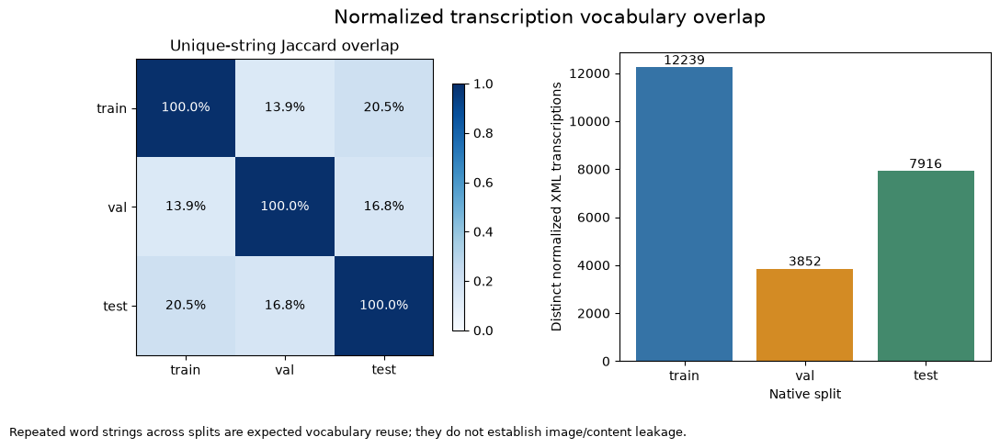

In [10]:
diff = c[c.raw_label_differs].copy()
diff['xml_normalized'] = diff.xml_text.map(normalize_text)
diff['crop_normalized'] = diff.text.map(normalize_text)
diff['slash_rewrite_explains'] = diff.xml_normalized.str.replace('/','-',regex=False)==diff.crop_normalized
assert len(diff)==238 and diff.slash_rewrite_explains.all()
table(diff[['crop_id','assigned_object_id','xml_text','text','xml_normalized','crop_normalized','slash_rewrite_explains']],'all-238-crop-xml-label-differences')
table(diff.groupby('split').size().reset_index(name='label_differences'),'transcription-source-differences-by-split')
print('Spotting GT remains raw XML. Recognition results retain their original crop-index references.')
figure(plot_vocabulary(data),'09-vocabulary-overlap')

## 5. Chất lượng ảnh — proxy và gallery
Grayscale SD và Laplacian variance là mô tả cường độ/cạnh, chưa hiệu chuẩn theo độ đọc được hoặc OCR accuracy. Không dùng các proxy để loại test frame hay chọn model.
Các gallery QC ở dưới có đủ mẫu cho 24 khóa học, gồm các vùng chữ nhỏ/trung bình/lớn theo quy tắc đã khai báo trước review.

**crop-image-proxy-summary: 3 rows exported; 3 shown.**

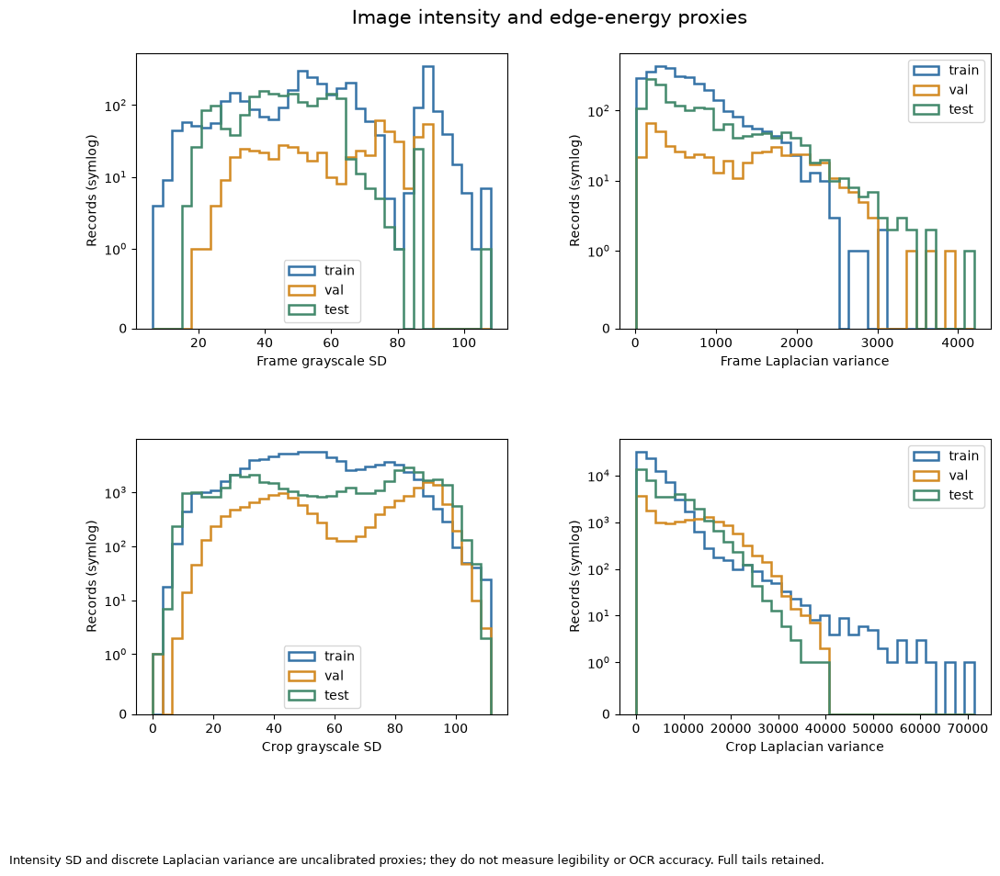

In [11]:
table(c.groupby('split')[['gray_std','laplacian_variance','width','height']].describe().round(3).reset_index(),'crop-image-proxy-summary')
figure(plot_quality(data),'10-intensity-and-edge-proxies')

## 6. Trùng lặp và review toàn bộ hàng đợi gần trùng
Exact duplicate của frame và lặp crop/word là hai hiện tượng khác nhau. Từ/crop giống nhau không tự chứng minh trùng video.
Tất cả 469 cặp dHash<=6 đã được xem trực quan; quyết định chỉ giải quyết hàng đợi này, không chứng nhận recall của phép sàng lọc hoặc độc lập nguồn.

In [12]:
assert not f.image_sha256.duplicated().any() and not f.pixel_key.duplicated().any()
duplicates = c.groupby('pixel_key').agg(crops=('crop_id','size'),splits=('split','nunique'),label_variants=('normalized_text','nunique')).reset_index()
table(duplicates[duplicates.crops>1],'all-exact-crop-pixel-repeat-groups',preview=24)
pairs,semantic = verify_reviews(f,o)
rows = f[['frame_id','split','dhash']].to_dict('records')
screened = {tuple(sorted((a['frame_id'],b['frame_id']))) for i,a in enumerate(rows) for b in rows[i+1:]
    if a['split']!=b['split'] and (int(a['dhash'],16)^int(b['dhash'],16)).bit_count()<=6}
assert screened=={tuple(sorted((r.left,r.right))) for r in pairs.itertuples()}
table(pairs.groupby('decision').size().reset_index(name='pairs'),'visual-pair-review-summary')
table(pairs[['pair_id','left','right','decision','rationale','uncertainty']],'all-469-pair-adjudications')

**all-exact-crop-pixel-repeat-groups: 79 rows exported; 24 shown.**

pixel_key,crops,splits,label_variants
111x36:606f03297333355dca4a3b2218cea483619cffffe2793cf131260010fe9df23f,2,1,1
112x30:a1fc90303f4b64f1a35e85562c804dd9e3f807f62d9c21758f0a2fbdebaccc49,3,1,1
119x24:385a25226da223173462769f3e60ee0681e7fcf863ba259132f0e6e871691f0f,2,1,1
11x11:27e110a3292dc482df7df8e2622696307b51a6a523b189c1cd11315b084efd19,2,1,1
11x12:2a3afc67c7e1fc40f9619f68378c6d9c9eb357e9eb0218752c75234acb289214,5,1,1
11x12:b674ac486a489407fb25c90a4d7d050b37da05535d9fcbd9da7ea976f62602b2,2,1,1
11x12:c6b090f089b45bffe6f0b89970675df8129ba9b82bcbfdacb3ef3f19c6221c67,2,1,1
11x12:d3e262d4e4501dd9aecc7f6a1b42dcf9642ed86f805ccfa326d4b71dcbd3bd47,2,1,1
11x13:cd1fc134a23bf64ad8b7194714688a622c8425c79274706e62ca29a52c086df0,2,1,1
11x14:e75b43fd5650cad17d53f9f2fcf7831d91e9b21e27d729da39a1f6ab1fda86f2,2,1,2


**visual-pair-review-summary: 1 rows exported; 1 shown.**

decision,pairs
different_observed_content,469


**all-469-pair-adjudications: 469 rows exported; 469 shown.**

pair_id,left,right,decision,rationale,uncertainty
pair-0000,train/16/18/00_12_50_00002.png,test/10/29/00_09_30_00002.png,different_observed_content,"Left shows organic reaction structures; right shows I/O, interrupt, DMA, disk or bus writing/diagrams. Visible writing and diagram content differ; no matching board/slide content observed.",No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0001,train/16/18/00_12_50_00002.png,test/10/3/00_29_28_00005.png,different_observed_content,"Left shows organic reaction structures; right shows computer organization, I/O or device-driver writing. Visible writing and diagram content differ; no matching board/slide content observed.",No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0002,train/17/19/00_58_18_00007.png,test/10/32/00_29_17_00008.png,different_observed_content,"Left shows HMM backward algorithm; right shows I/O, interrupt, DMA, disk or bus writing/diagrams. Visible writing and diagram content differ; no matching board/slide content observed.",No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0003,train/17/21/00_49_27_00006.png,test/14/23/00_07_41_00003.png,different_observed_content,Left shows closed form solution and pseudoinverse; right shows algorithm/LCS/set-cover/tree writing or diagrams. Visible writing and diagram content differ; no matching board/slide content observed.,No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0004,train/17/22/01_05_42_00006.png,test/14/18/00_14_27_00004.png,different_observed_content,Left shows nearest neighbour classification scatter plot; right shows algorithm/LCS/set-cover/tree writing or diagrams. Visible writing and diagram content differ; no matching board/slide content observed.,No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0005,train/17/25/00_27_28_00005.png,test/14/23/00_07_41_00003.png,different_observed_content,Left shows Hopfield network associative memory nodes; right shows algorithm/LCS/set-cover/tree writing or diagrams. Visible writing and diagram content differ; no matching board/slide content observed.,No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0006,train/21/13/00_15_11_00005.png,test/14/18/00_14_27_00004.png,different_observed_content,Left shows domestic macroeconomy; right shows algorithm/LCS/set-cover/tree writing or diagrams. Visible writing and diagram content differ; no matching board/slide content observed.,No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0007,train/21/13/00_48_24_00010.png,test/14/18/00_14_27_00004.png,different_observed_content,Left shows economic forecasting; right shows algorithm/LCS/set-cover/tree writing or diagrams. Visible writing and diagram content differ; no matching board/slide content observed.,No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0008,train/21/14/00_06_17_00005.png,test/14/19/00_07_44_00004.png,different_observed_content,Left shows cyclical indicator approach; right shows algorithm/LCS/set-cover/tree writing or diagrams. Visible writing and diagram content differ; no matching board/slide content observed.,No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.
pair-0009,train/21/14/00_16_39_00009.png,test/14/19/00_07_44_00004.png,different_observed_content,Left shows inflation interest rates and security prices; right shows algorithm/LCS/set-cover/tree writing or diagrams. Visible writing and diagram content differ; no matching board/slide content observed.,No ambiguity in this observed difference; unscreened pairs and source-video identity outside review.


**pair-contact-sheets/page-001.jpg**

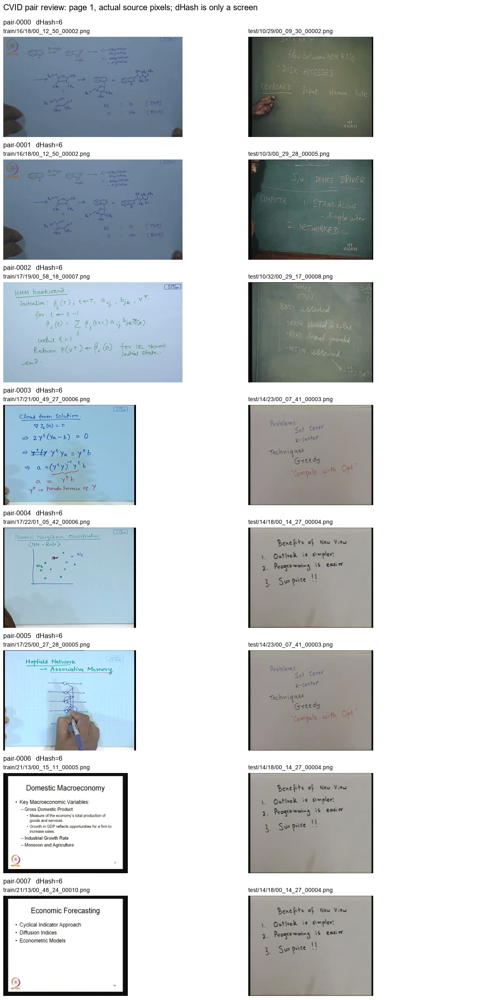

**pair-contact-sheets/page-002.jpg**

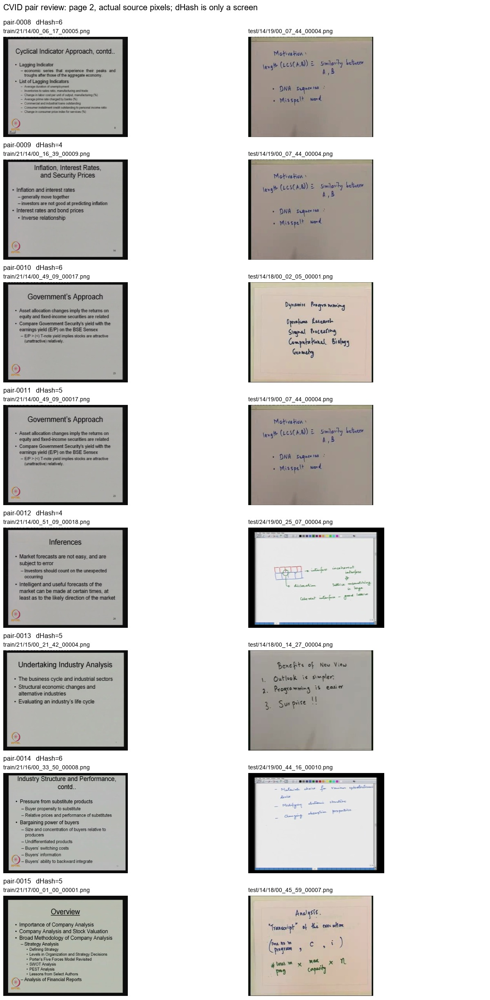

**pair-contact-sheets/page-003.jpg**

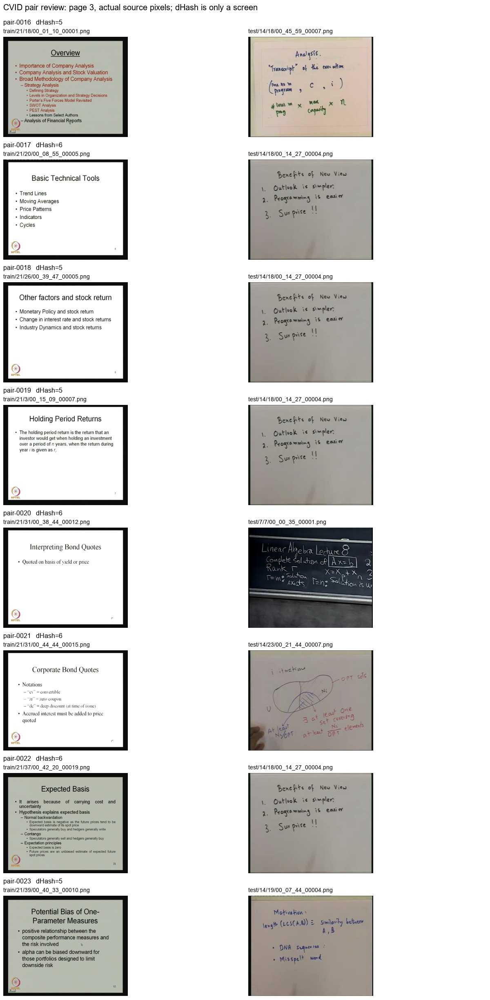

**pair-contact-sheets/page-004.jpg**

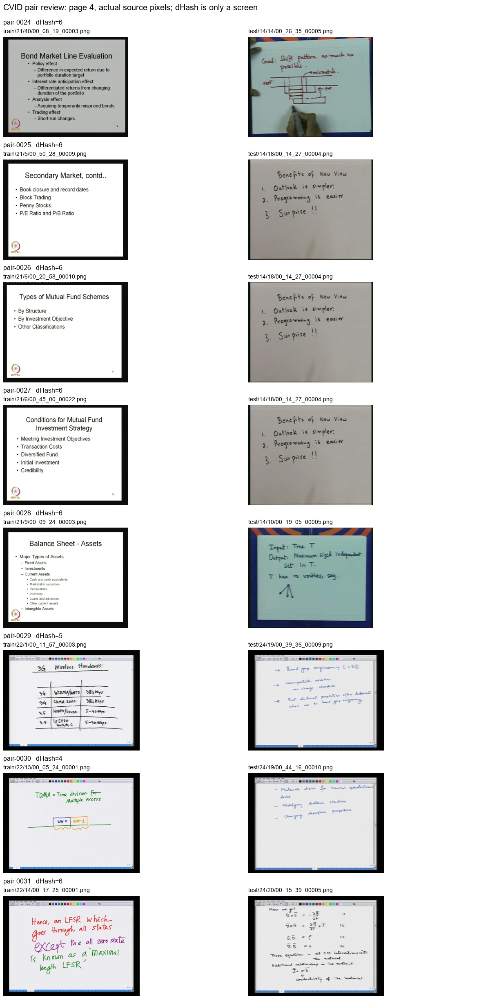

**pair-contact-sheets/page-005.jpg**

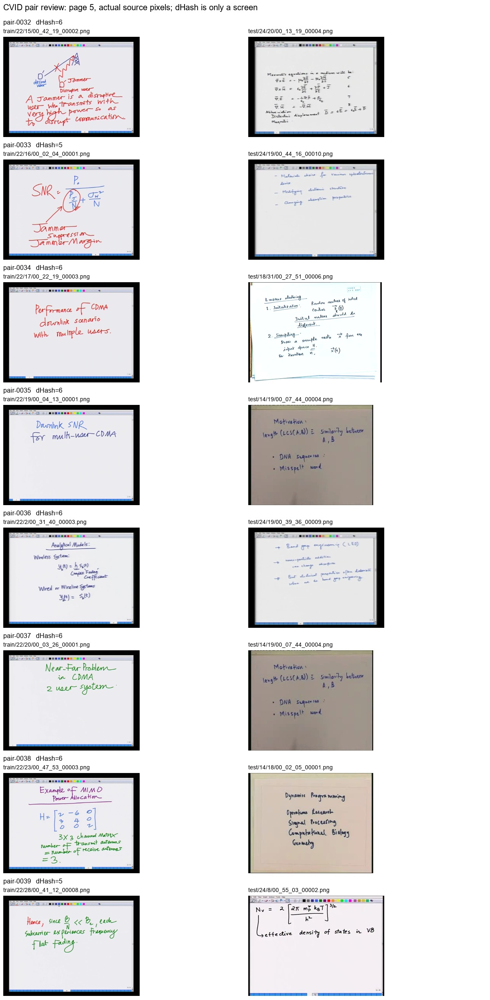

**pair-contact-sheets/page-006.jpg**

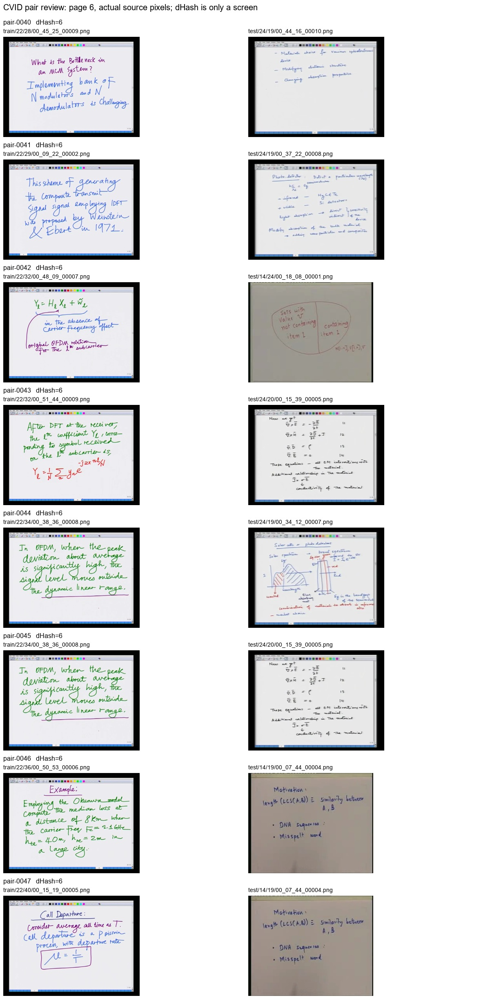

**pair-contact-sheets/page-007.jpg**

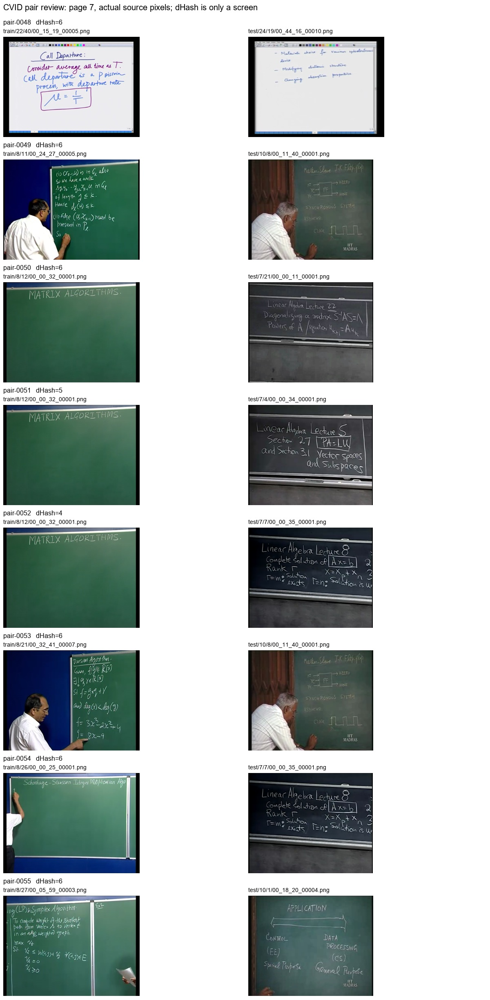

**pair-contact-sheets/page-008.jpg**

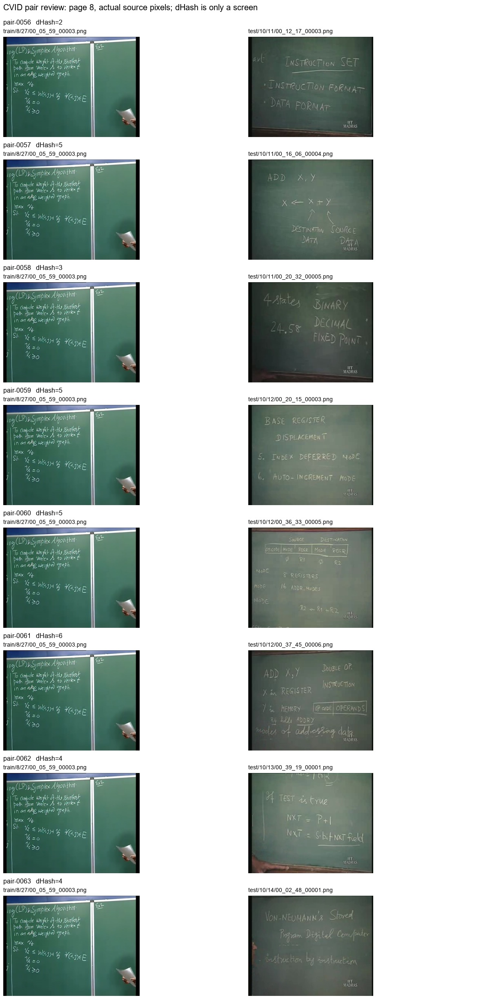

**pair-contact-sheets/page-009.jpg**

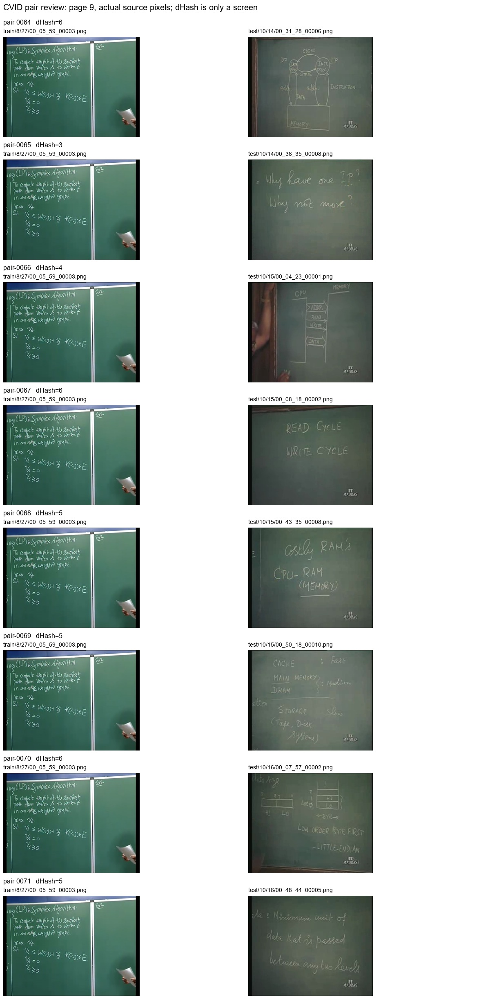

**pair-contact-sheets/page-010.jpg**

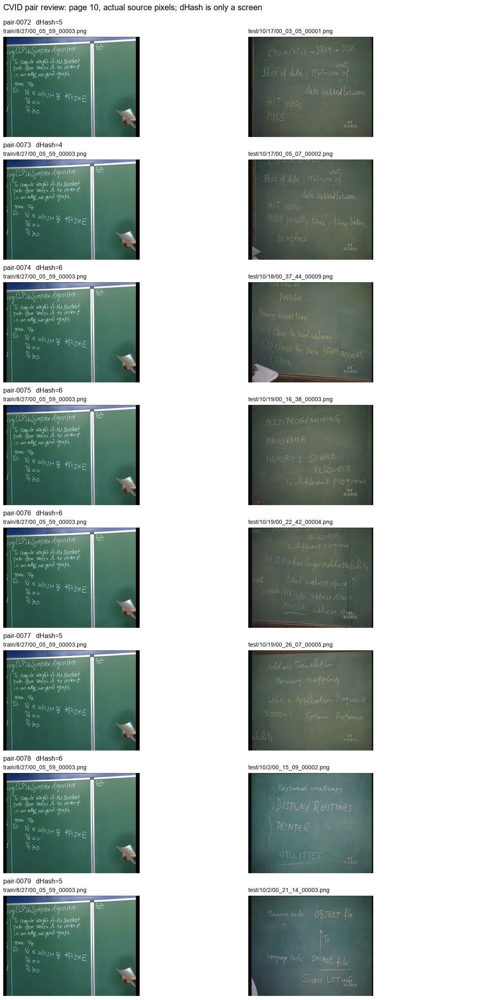

**pair-contact-sheets/page-011.jpg**

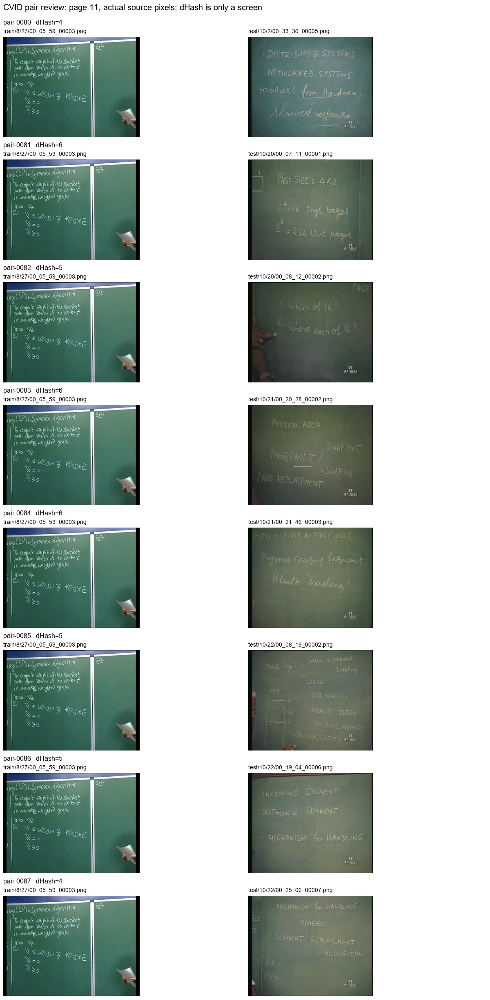

**pair-contact-sheets/page-012.jpg**

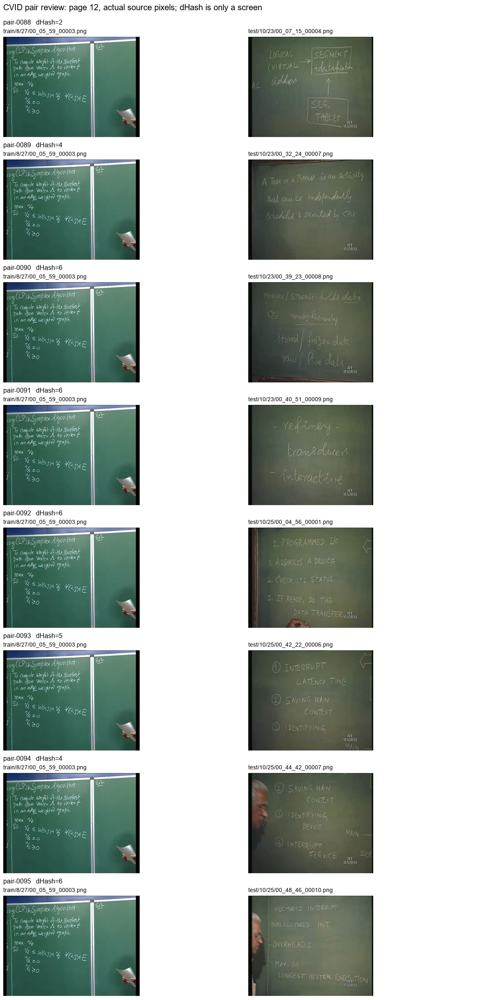

**pair-contact-sheets/page-013.jpg**

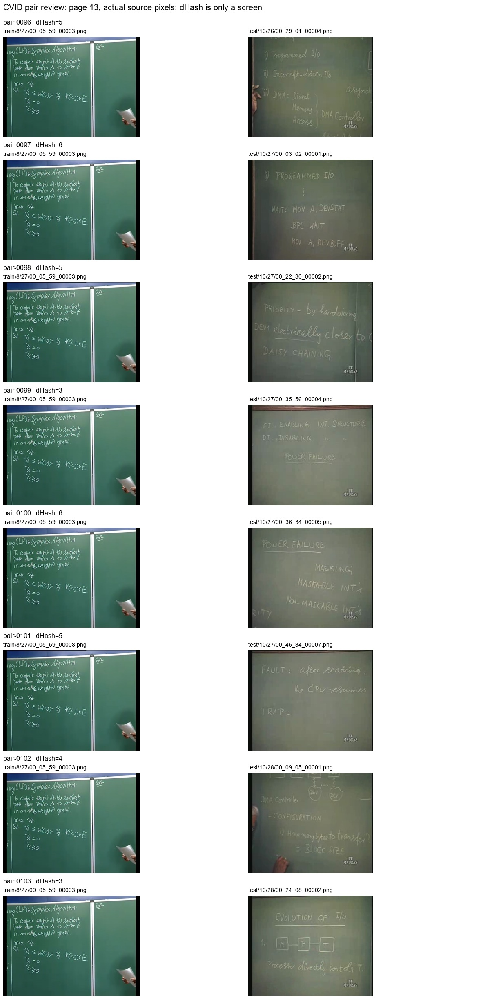

**pair-contact-sheets/page-014.jpg**

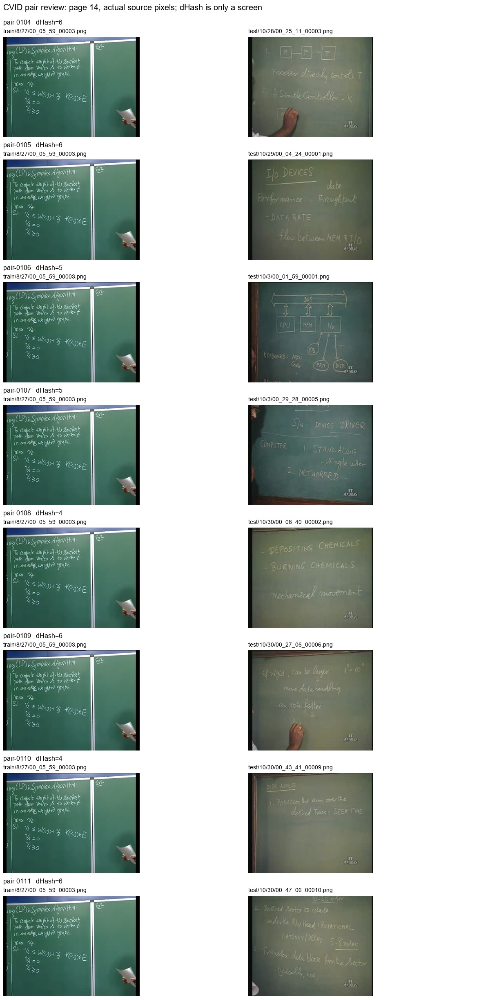

**pair-contact-sheets/page-015.jpg**

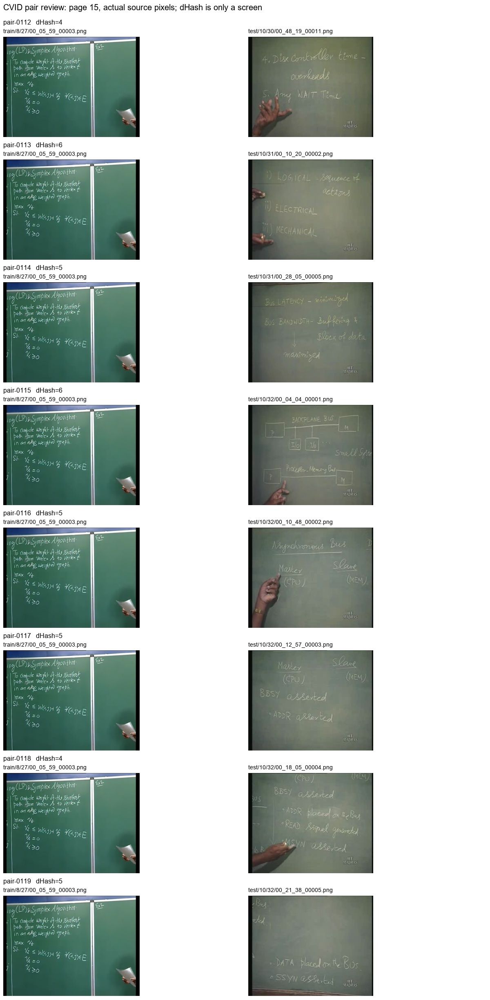

**pair-contact-sheets/page-016.jpg**

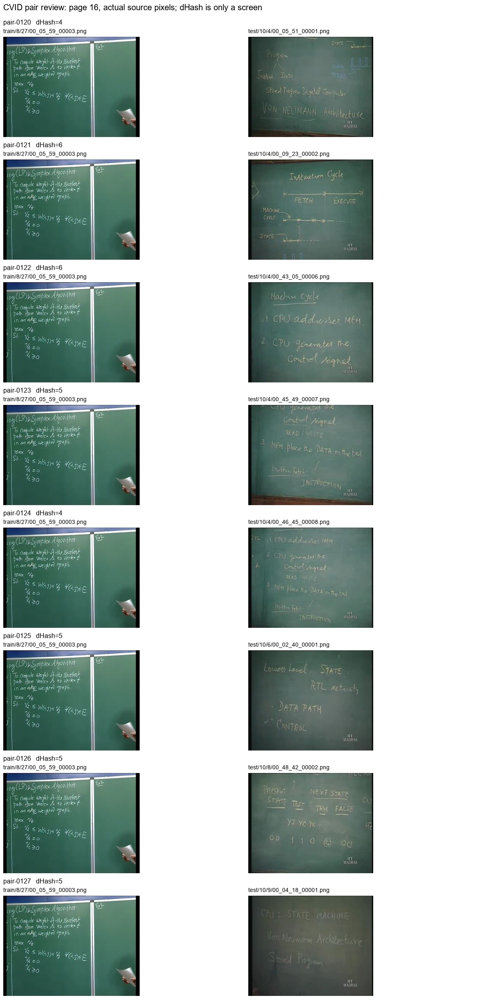

**pair-contact-sheets/page-017.jpg**

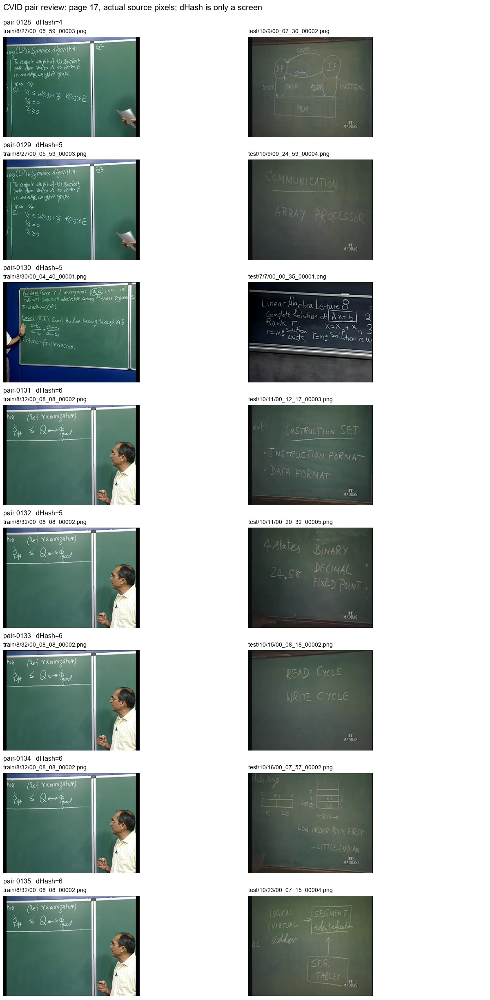

**pair-contact-sheets/page-018.jpg**

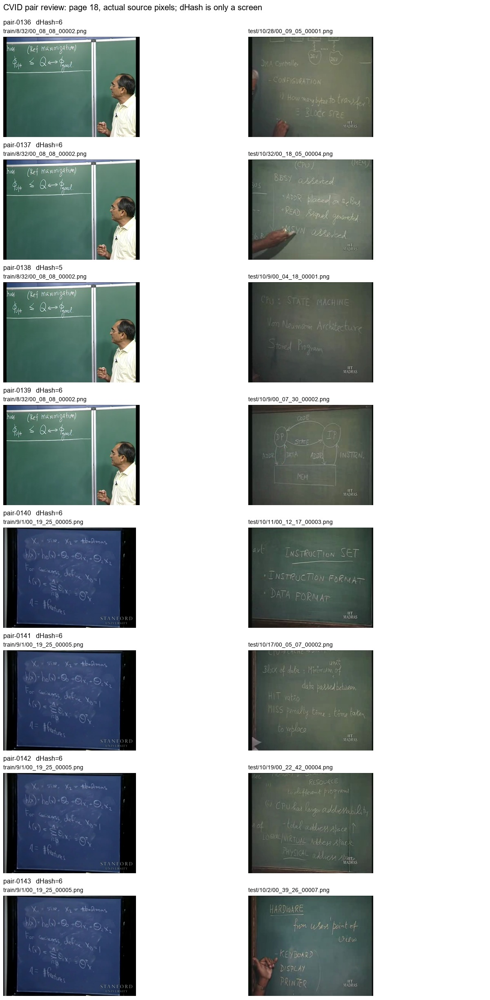

**pair-contact-sheets/page-019.jpg**

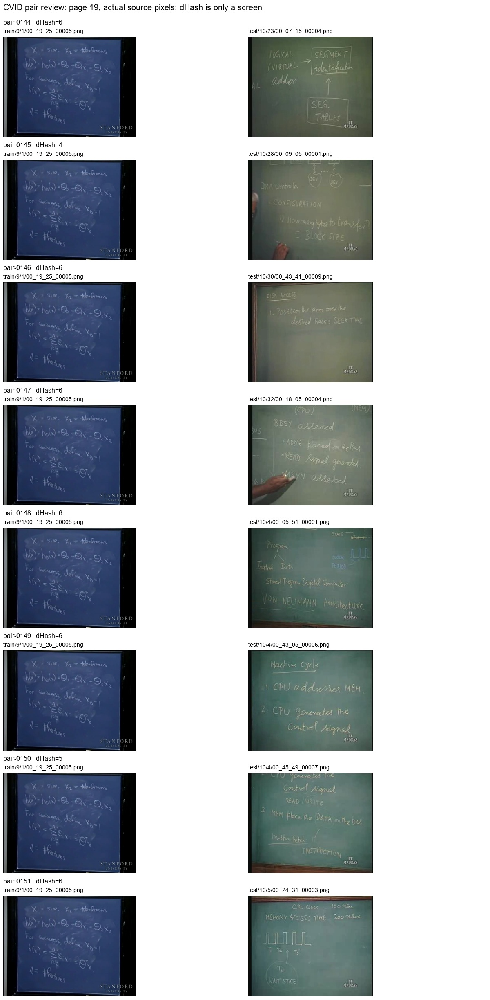

**pair-contact-sheets/page-020.jpg**

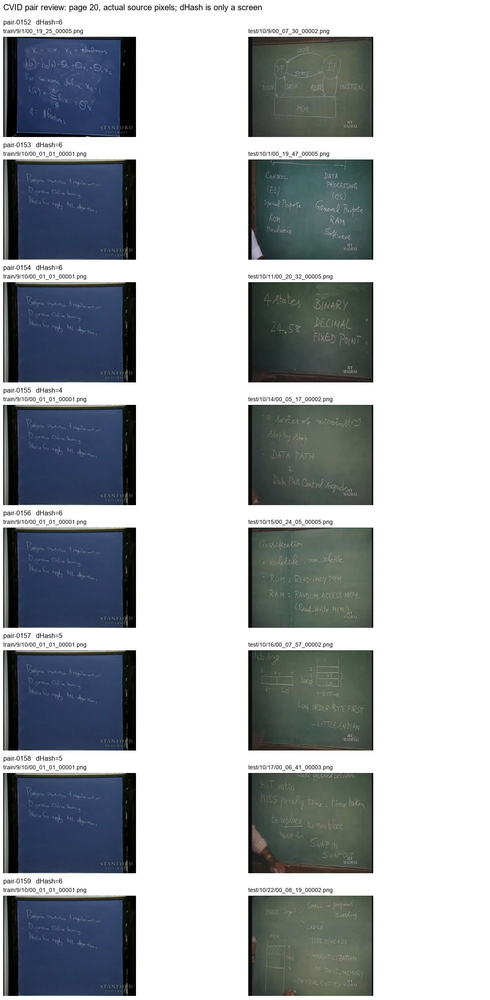

**pair-contact-sheets/page-021.jpg**

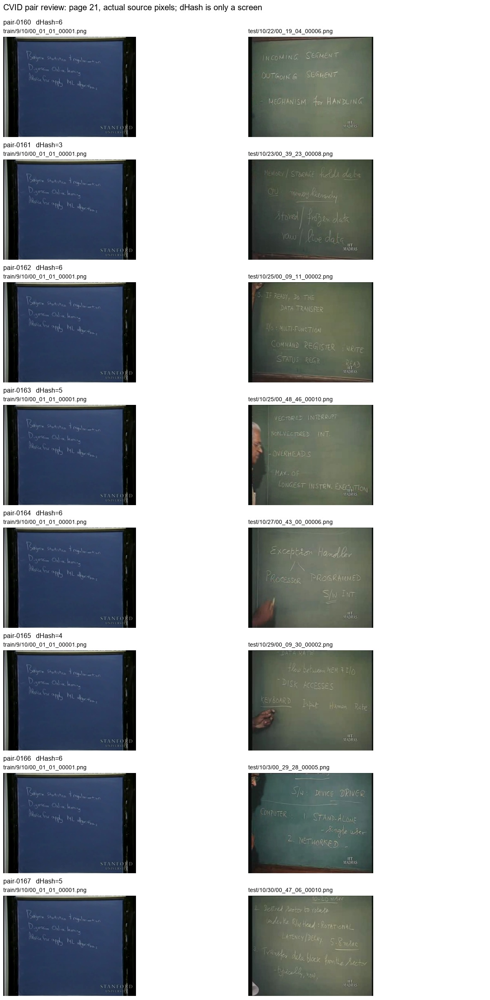

**pair-contact-sheets/page-022.jpg**

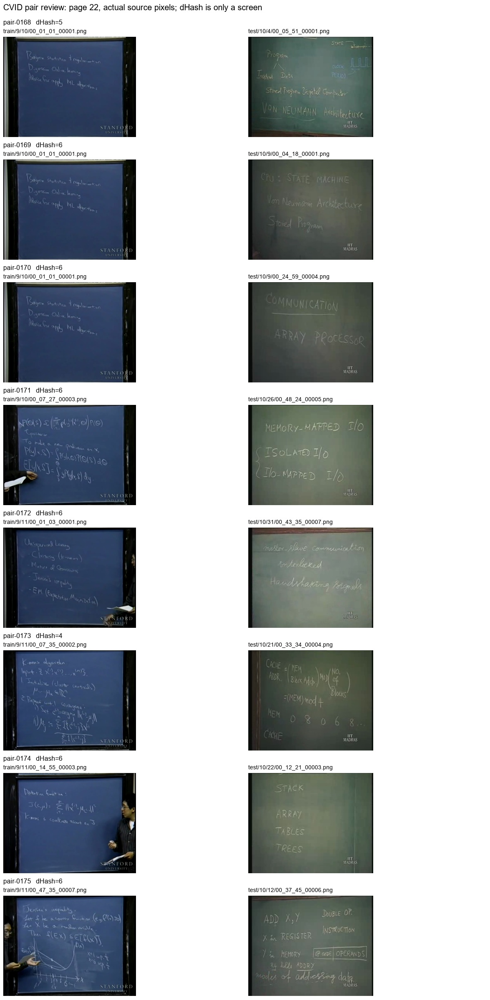

**pair-contact-sheets/page-023.jpg**

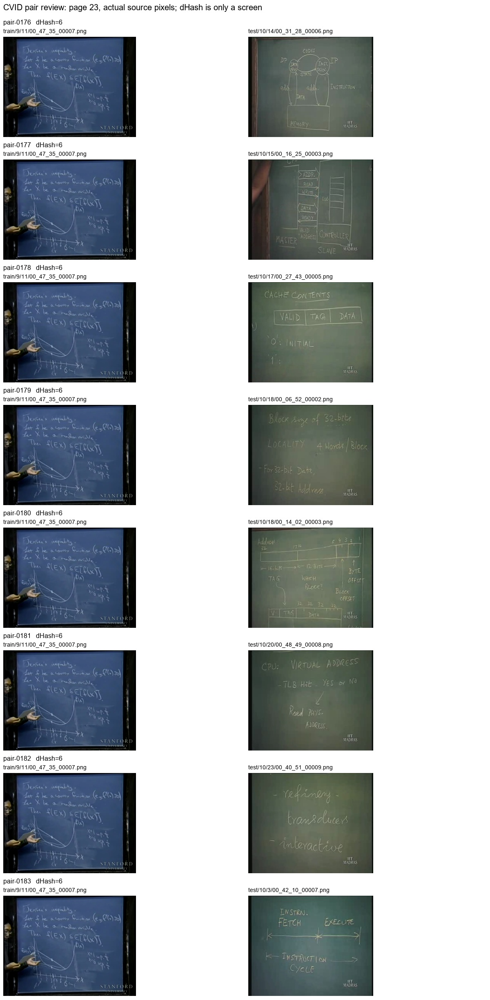

**pair-contact-sheets/page-024.jpg**

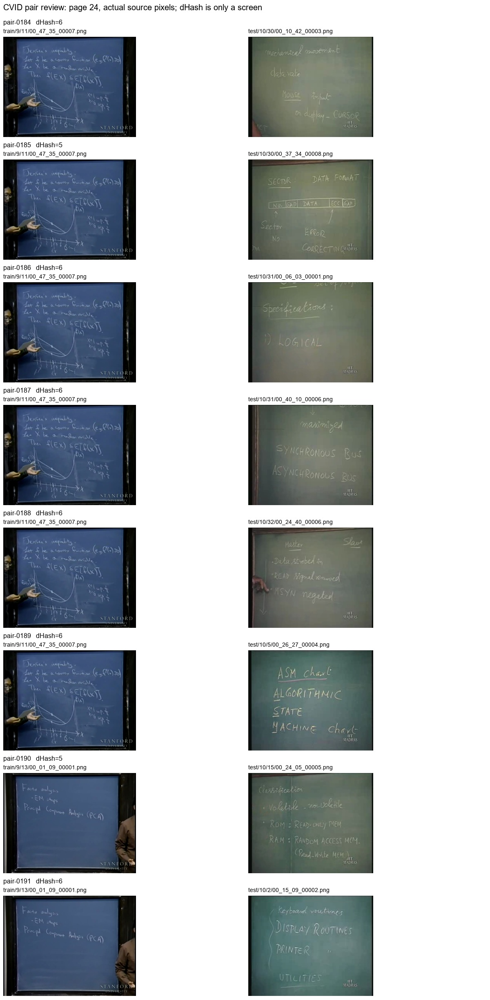

**pair-contact-sheets/page-025.jpg**

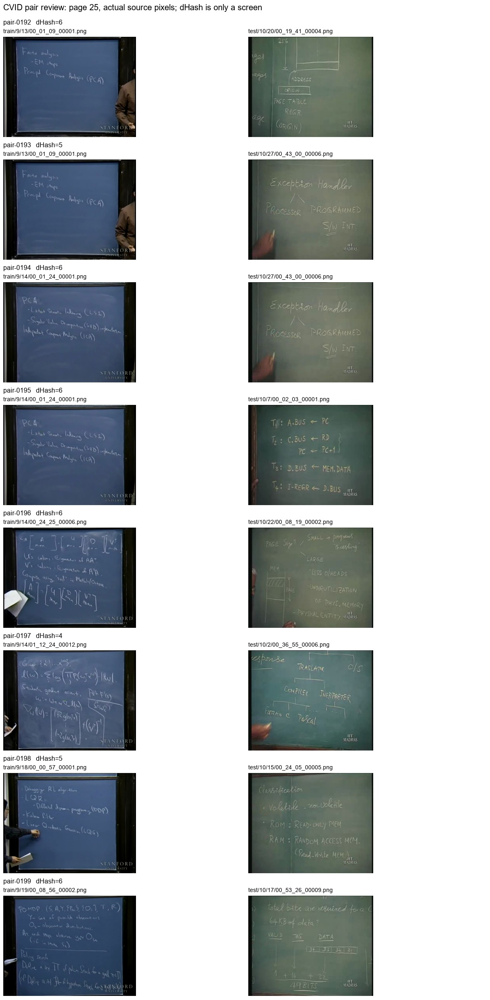

**pair-contact-sheets/page-026.jpg**

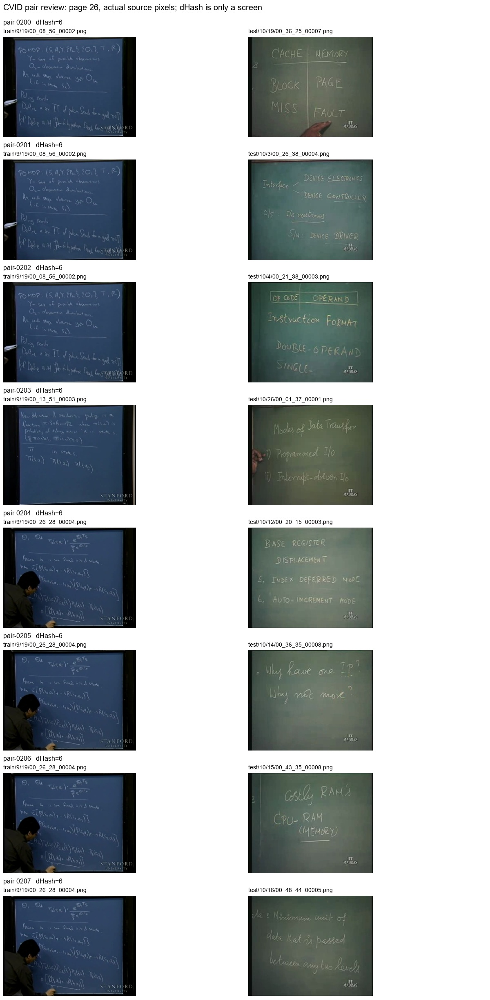

**pair-contact-sheets/page-027.jpg**

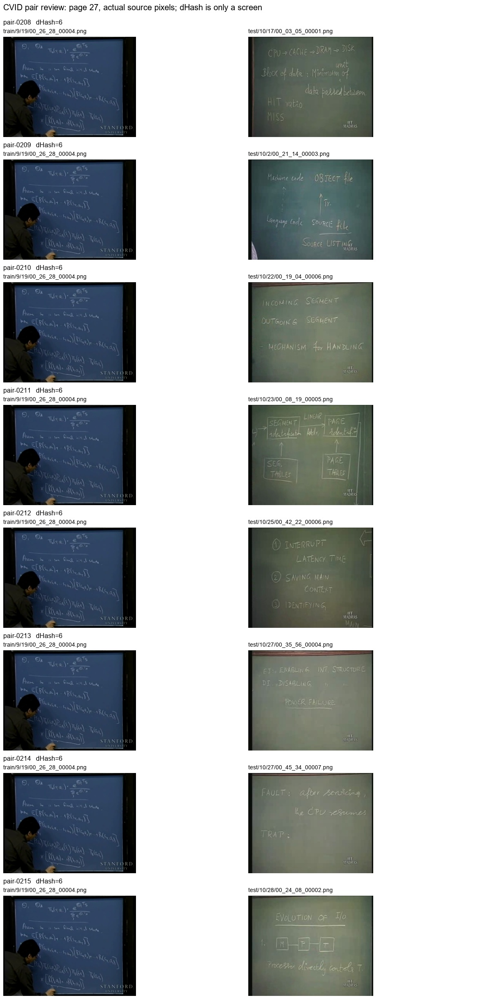

**pair-contact-sheets/page-028.jpg**

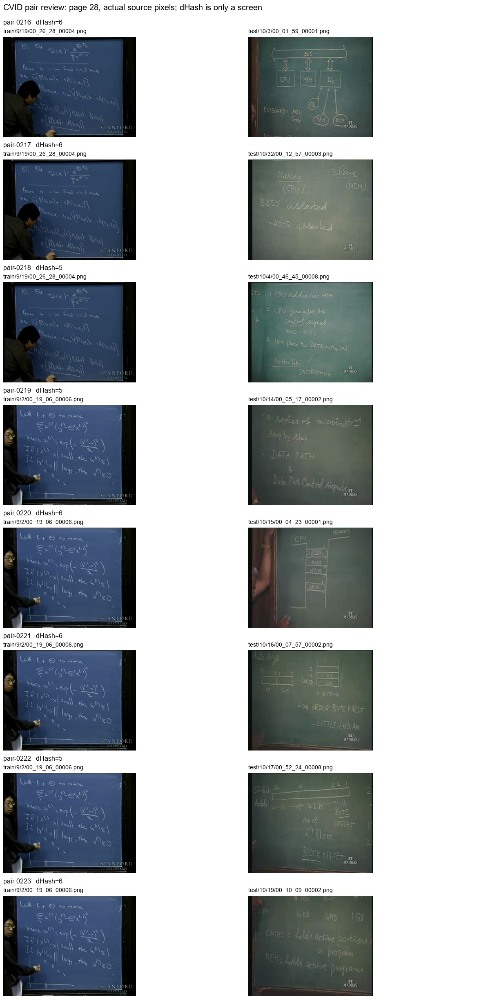

**pair-contact-sheets/page-029.jpg**

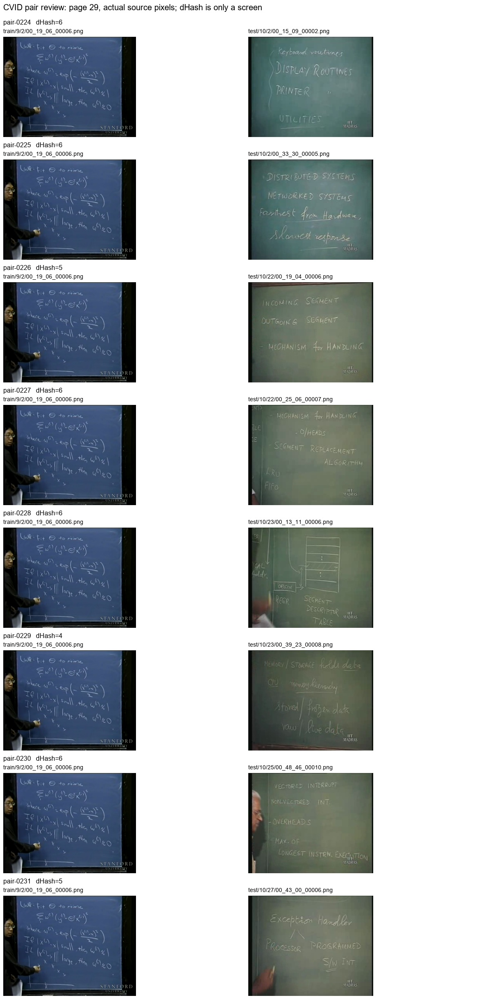

**pair-contact-sheets/page-030.jpg**

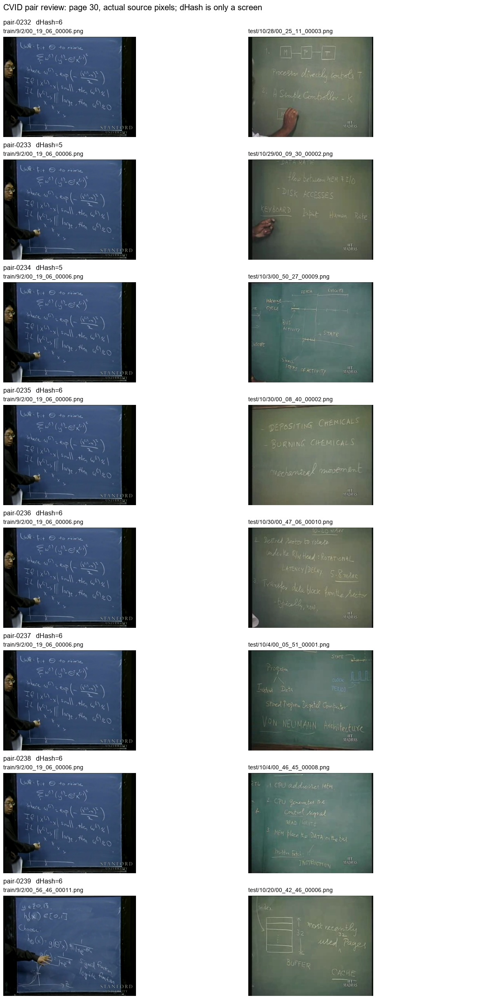

**pair-contact-sheets/page-031.jpg**

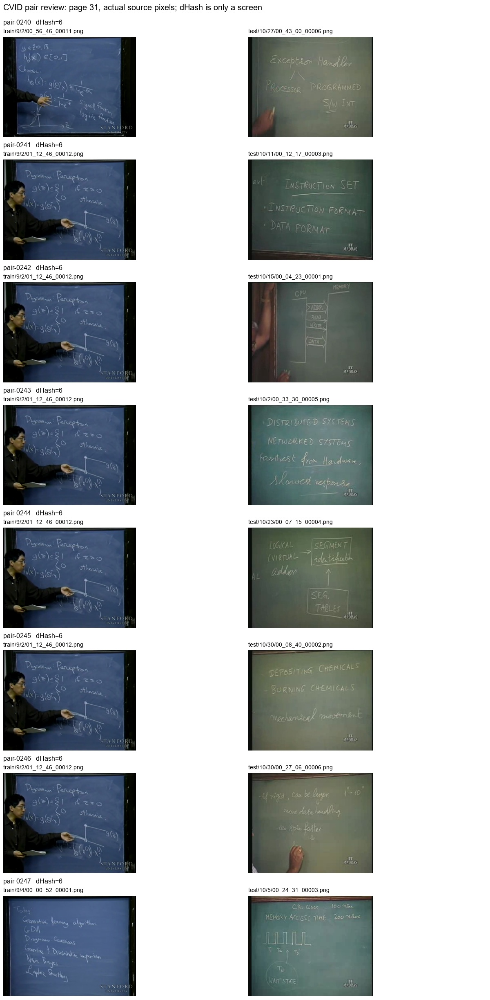

**pair-contact-sheets/page-032.jpg**

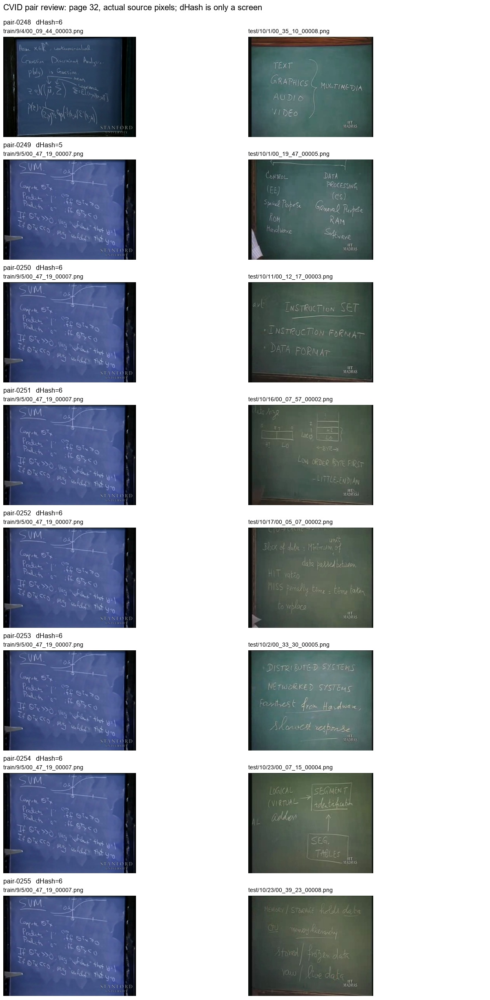

**pair-contact-sheets/page-033.jpg**

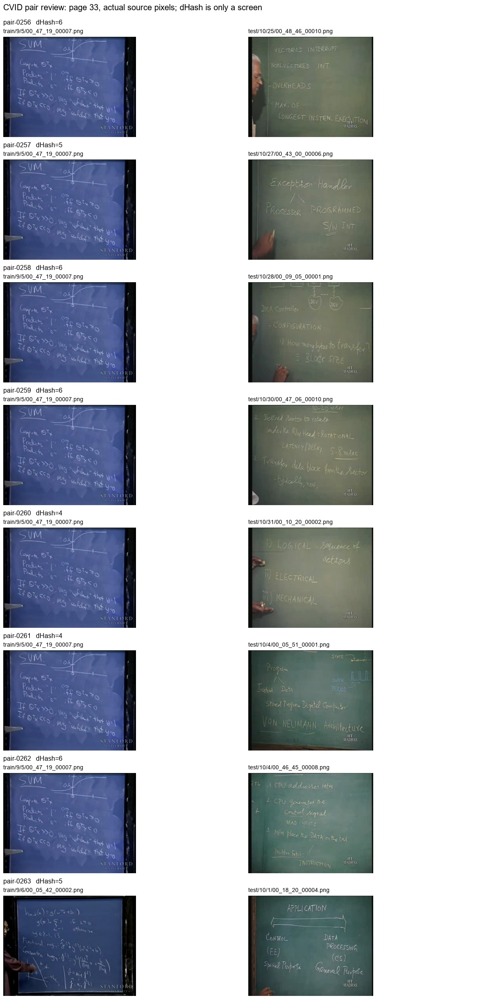

**pair-contact-sheets/page-034.jpg**

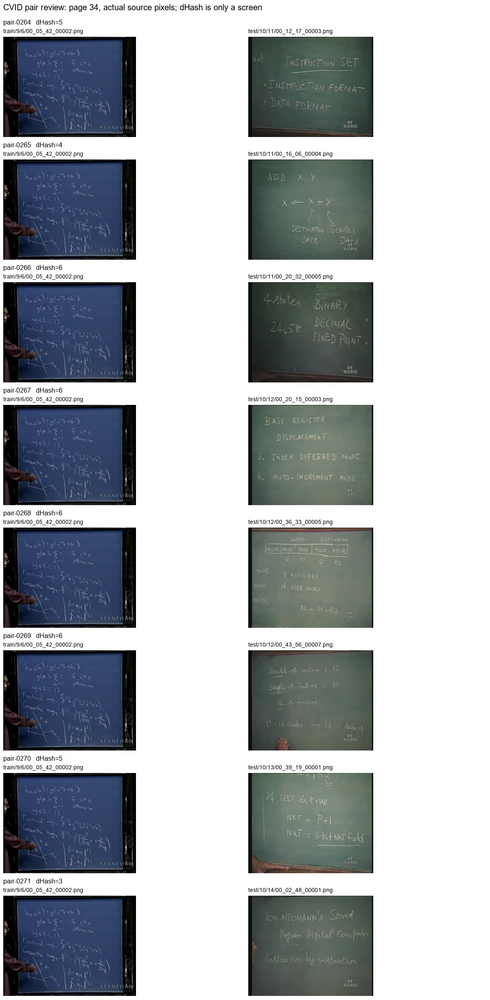

**pair-contact-sheets/page-035.jpg**

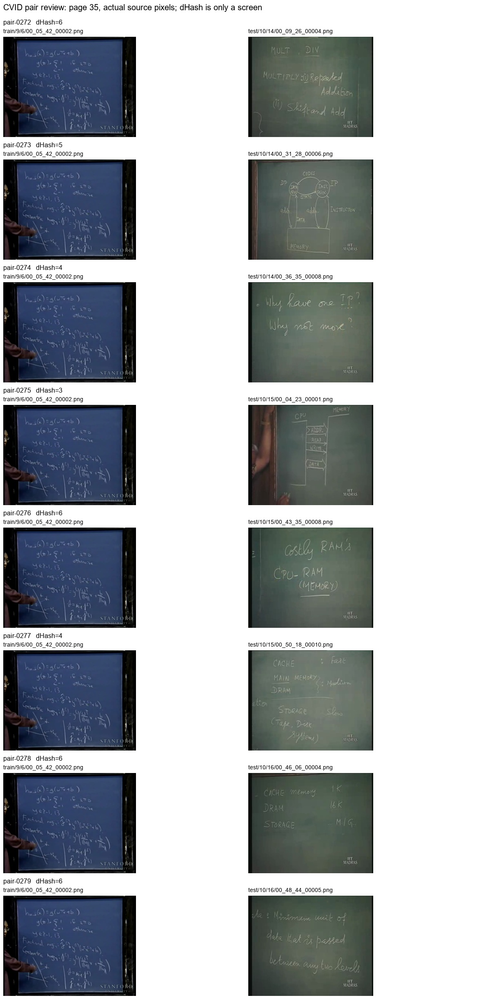

**pair-contact-sheets/page-036.jpg**

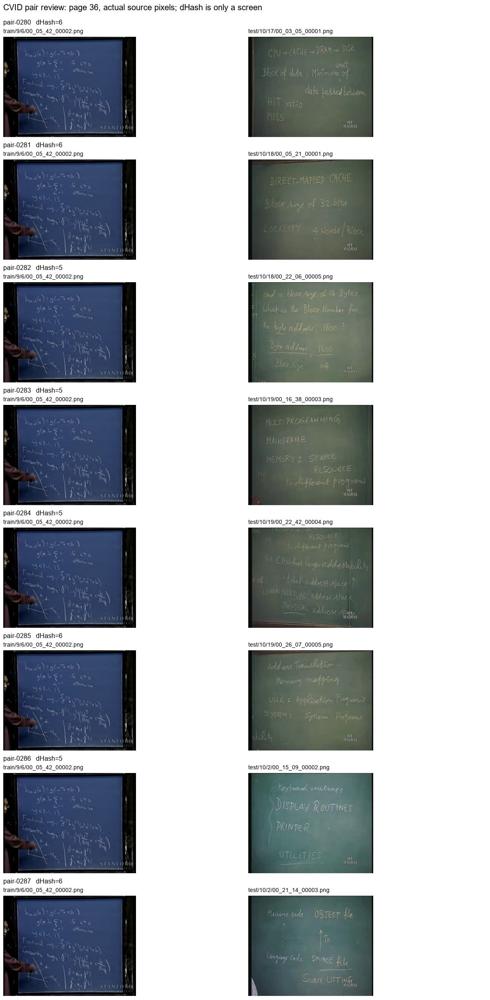

**pair-contact-sheets/page-037.jpg**

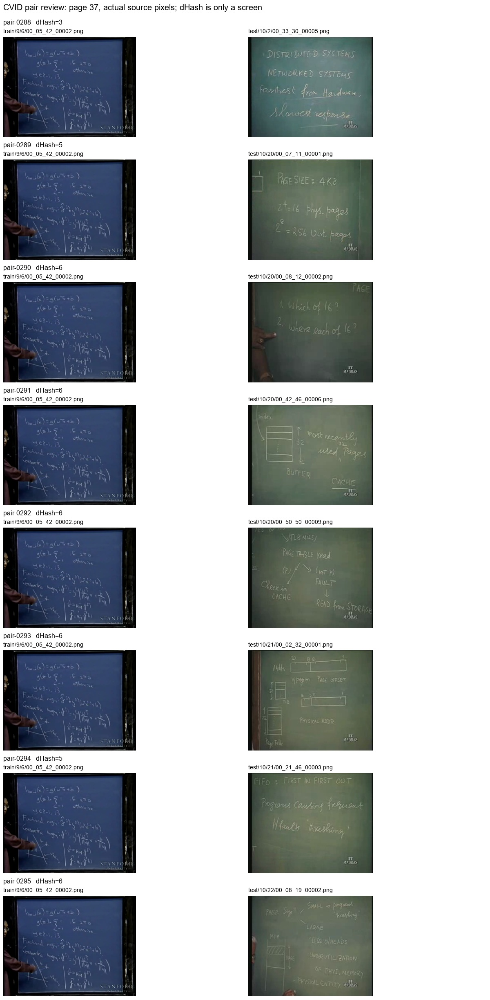

**pair-contact-sheets/page-038.jpg**

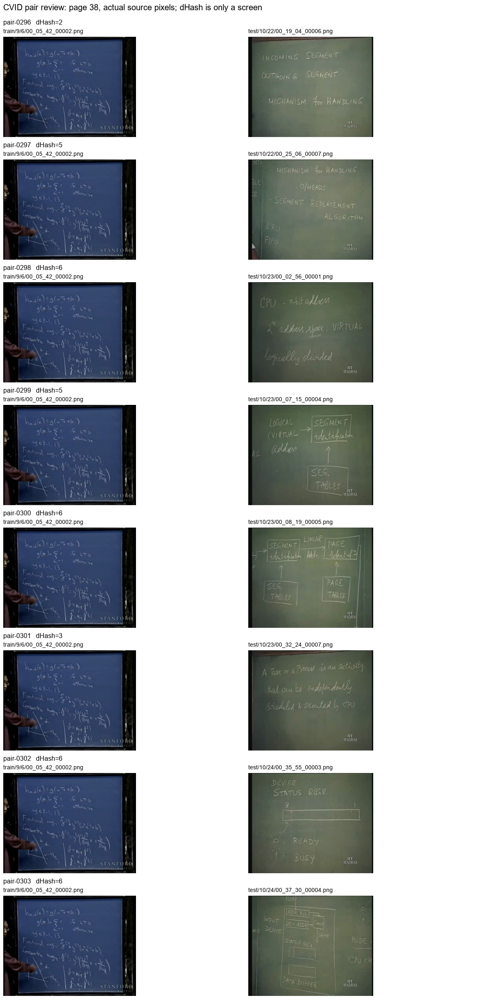

**pair-contact-sheets/page-039.jpg**

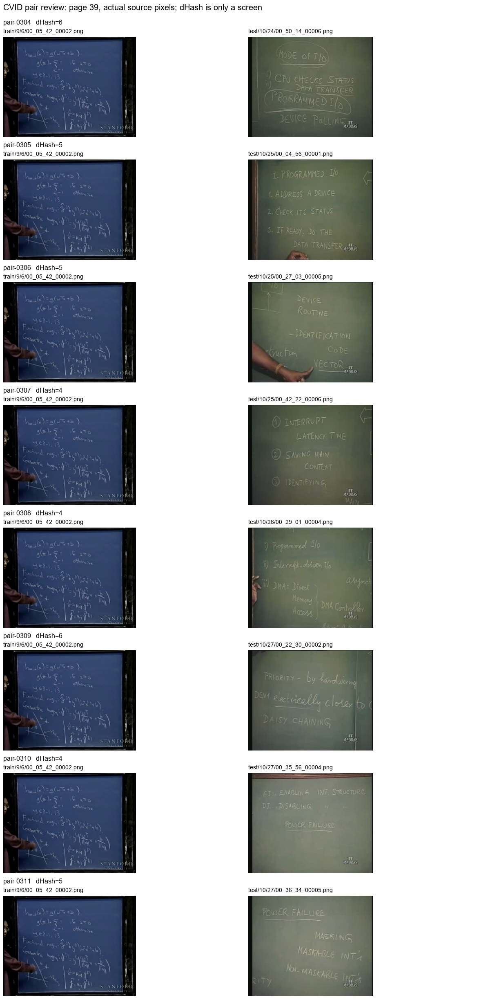

**pair-contact-sheets/page-040.jpg**

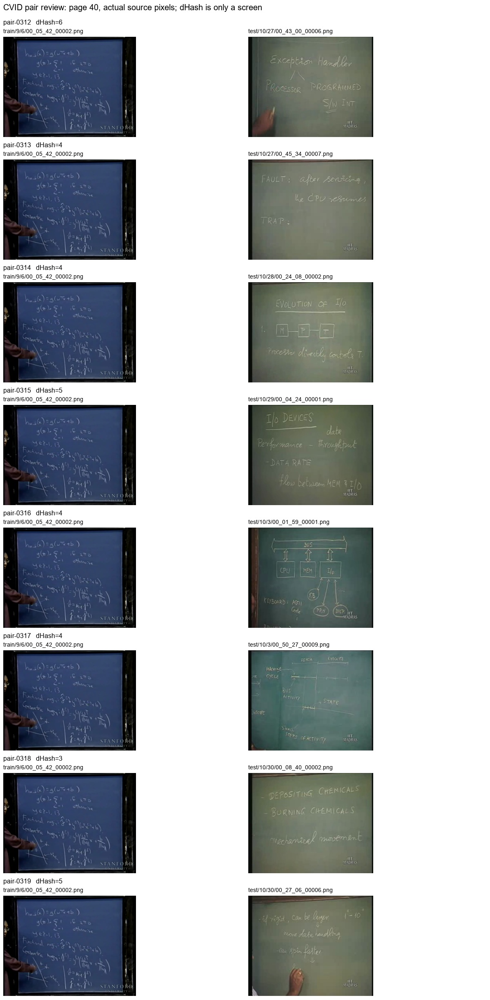

**pair-contact-sheets/page-041.jpg**

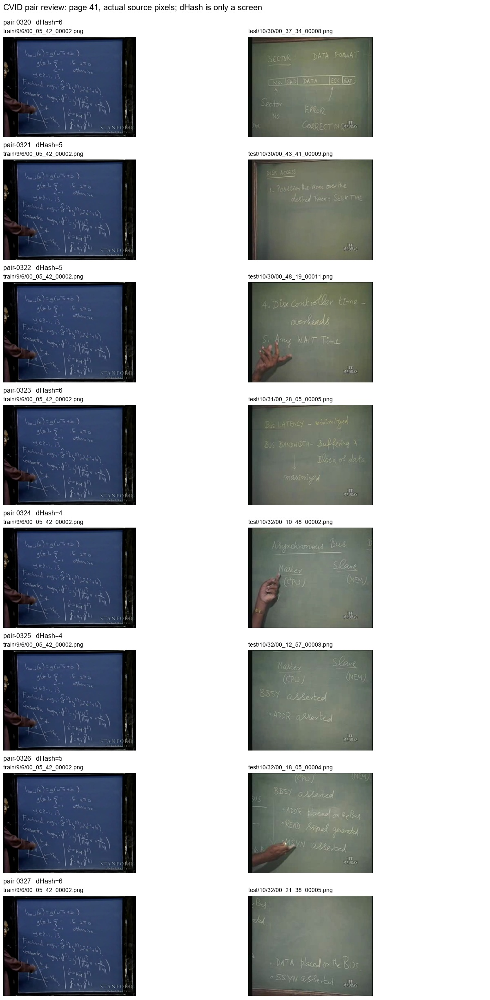

**pair-contact-sheets/page-042.jpg**

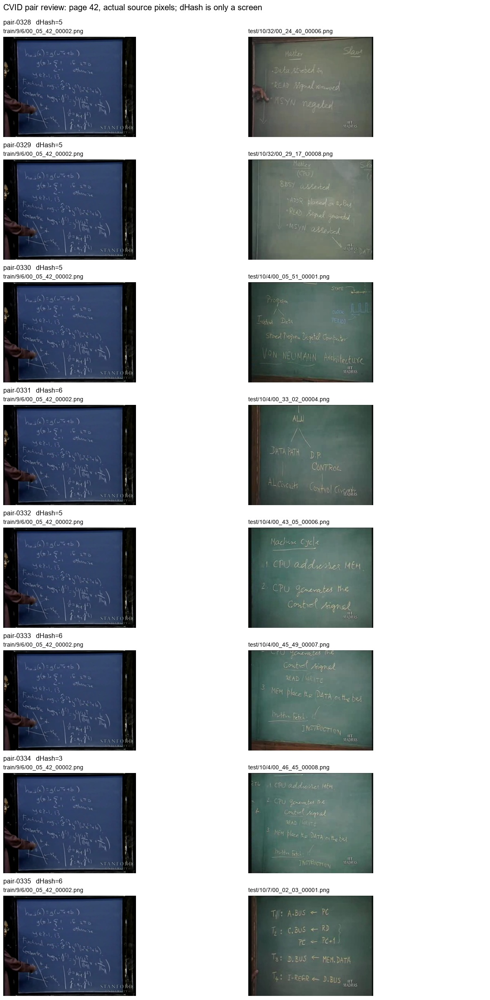

**pair-contact-sheets/page-043.jpg**

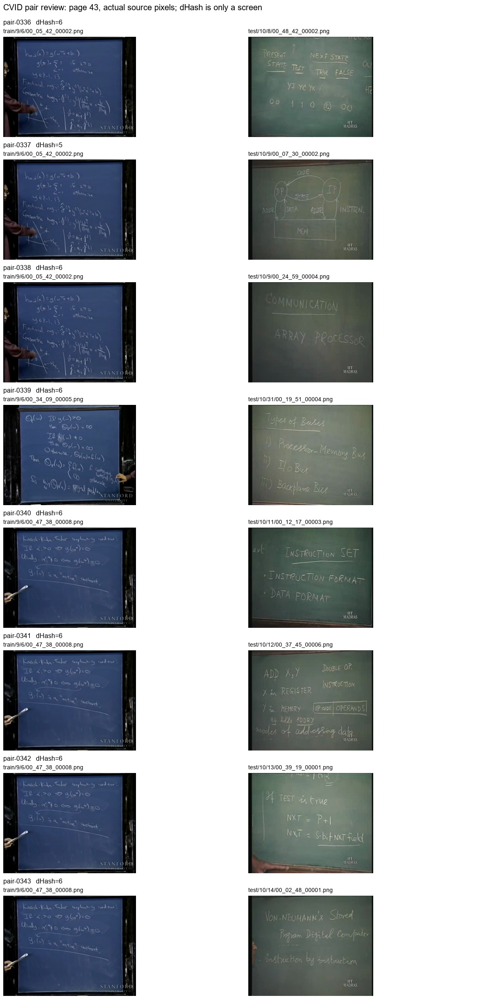

**pair-contact-sheets/page-044.jpg**

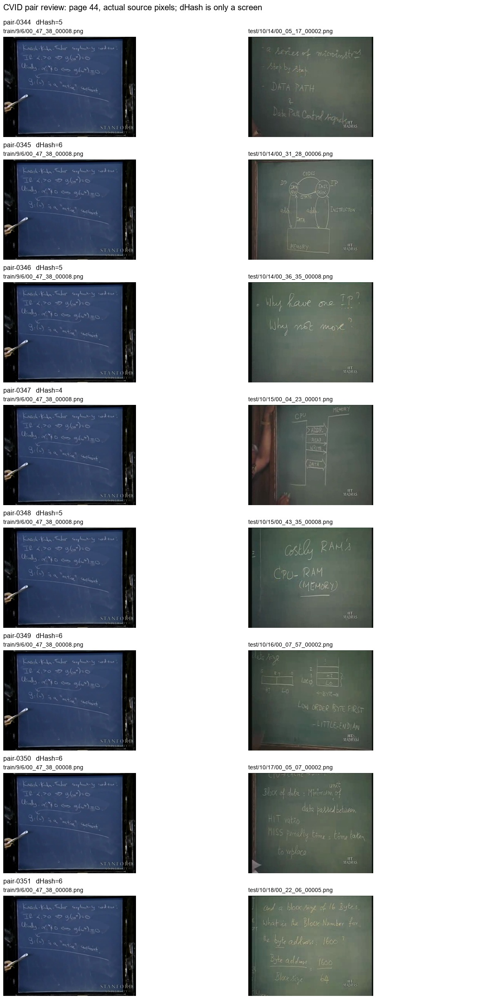

**pair-contact-sheets/page-045.jpg**

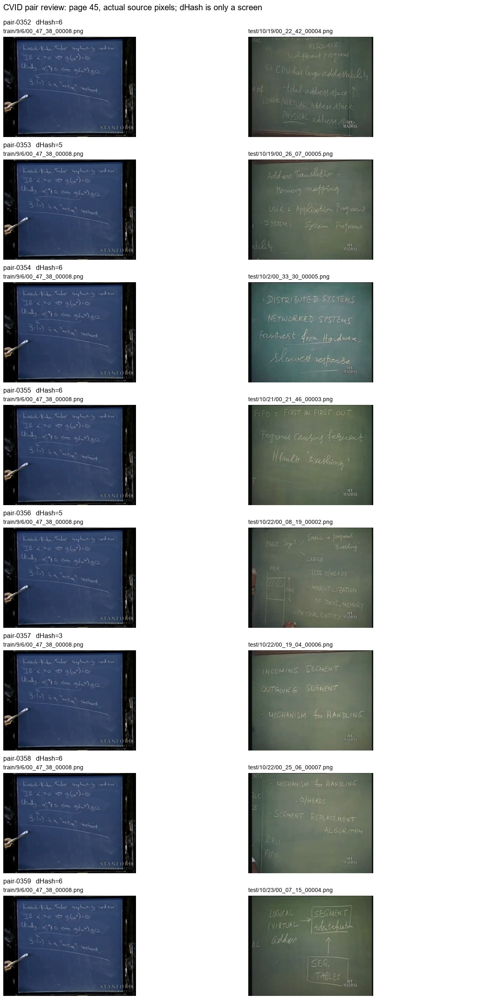

**pair-contact-sheets/page-046.jpg**

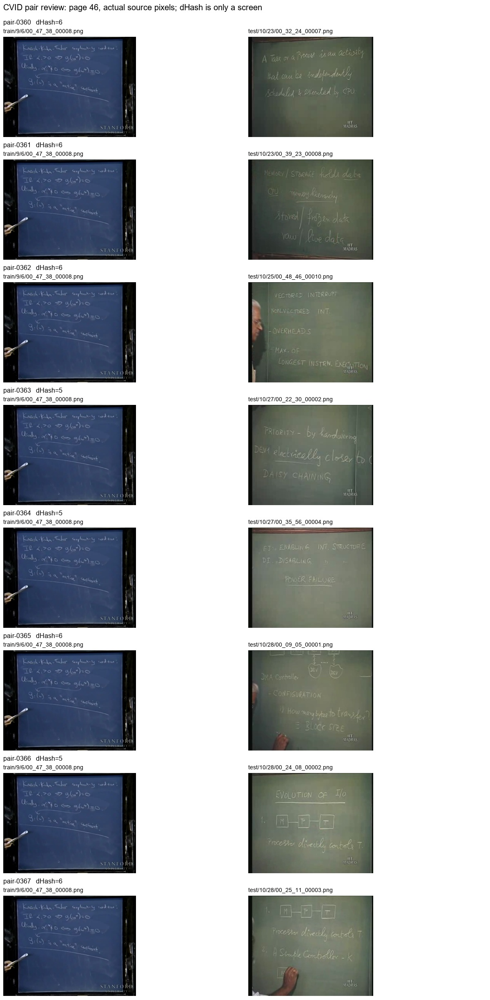

**pair-contact-sheets/page-047.jpg**

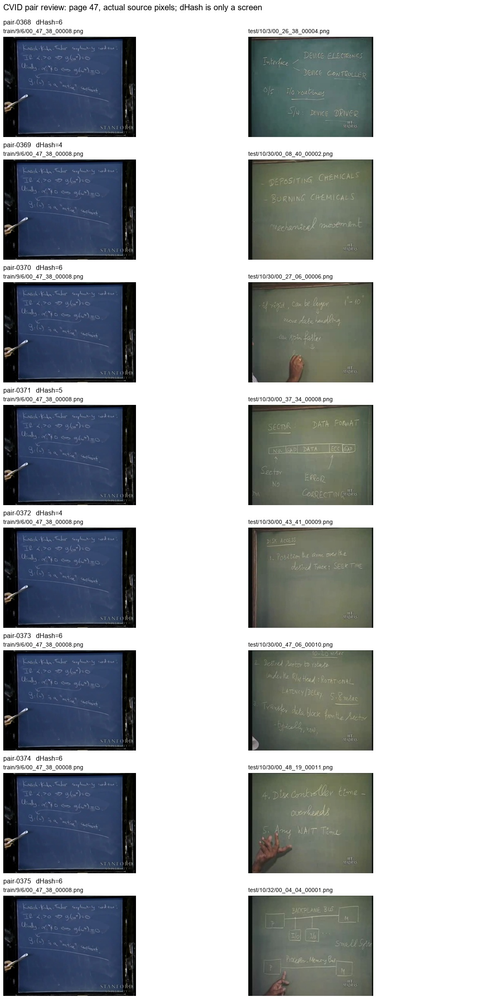

**pair-contact-sheets/page-048.jpg**

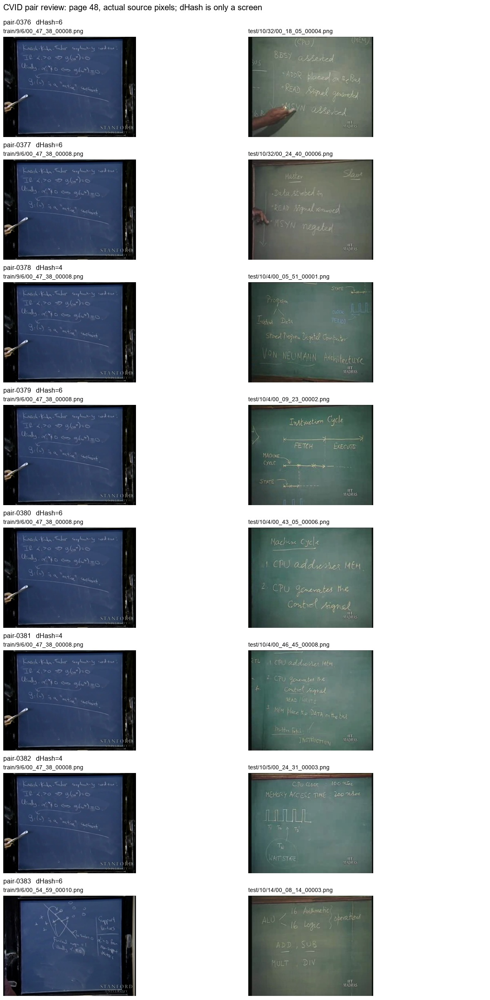

**pair-contact-sheets/page-049.jpg**

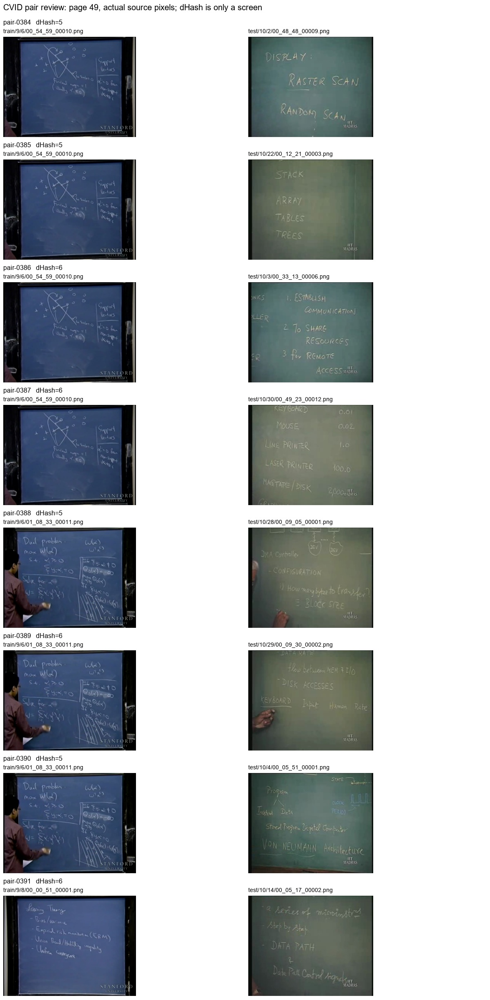

**pair-contact-sheets/page-050.jpg**

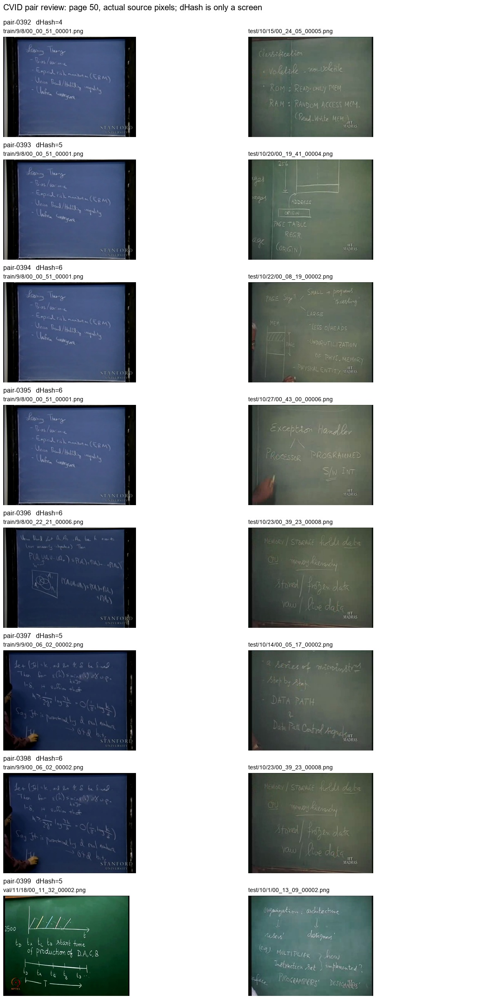

**pair-contact-sheets/page-051.jpg**

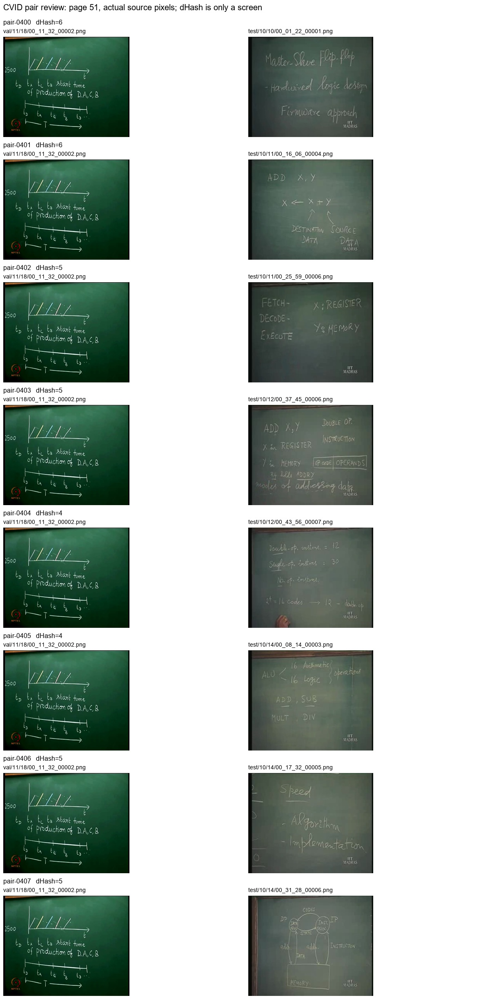

**pair-contact-sheets/page-052.jpg**

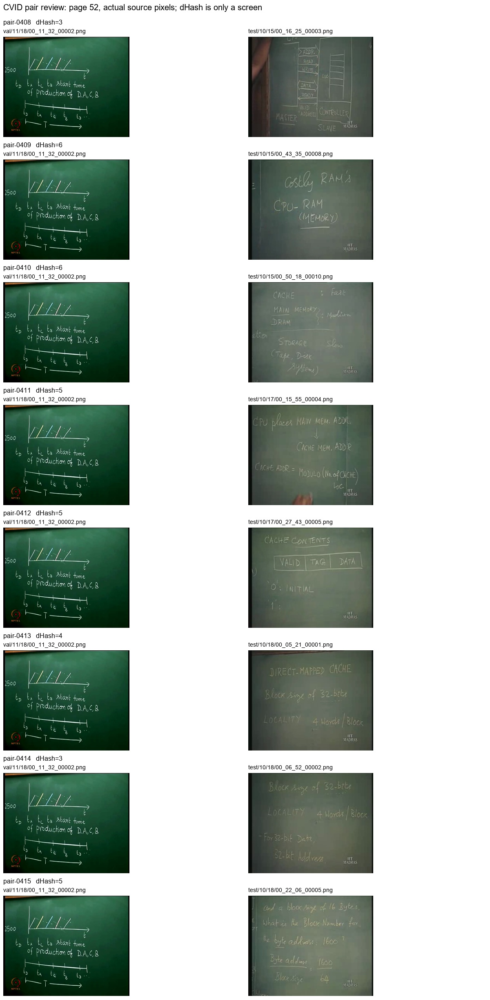

**pair-contact-sheets/page-053.jpg**

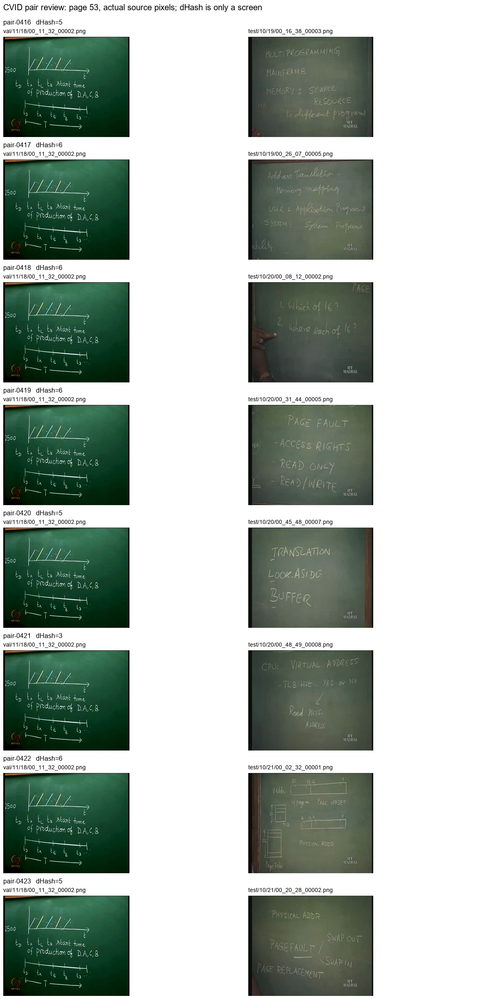

**pair-contact-sheets/page-054.jpg**

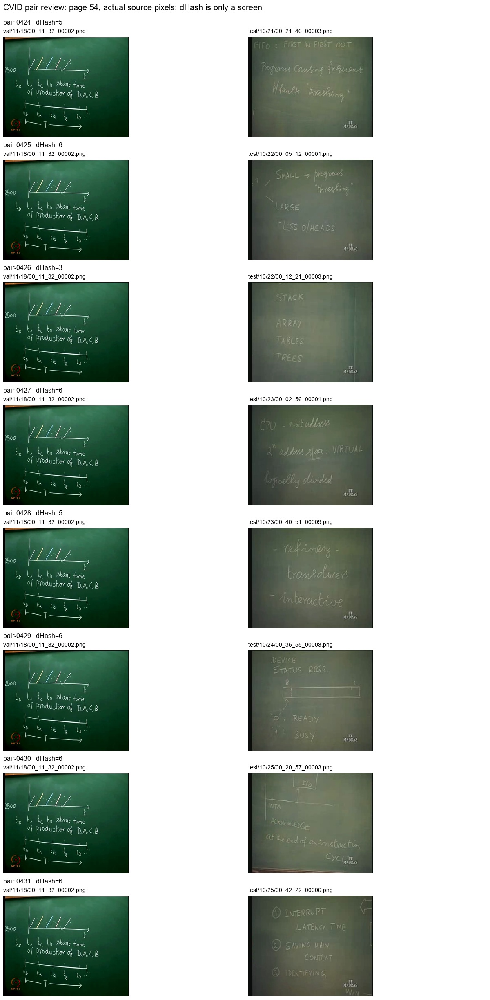

**pair-contact-sheets/page-055.jpg**

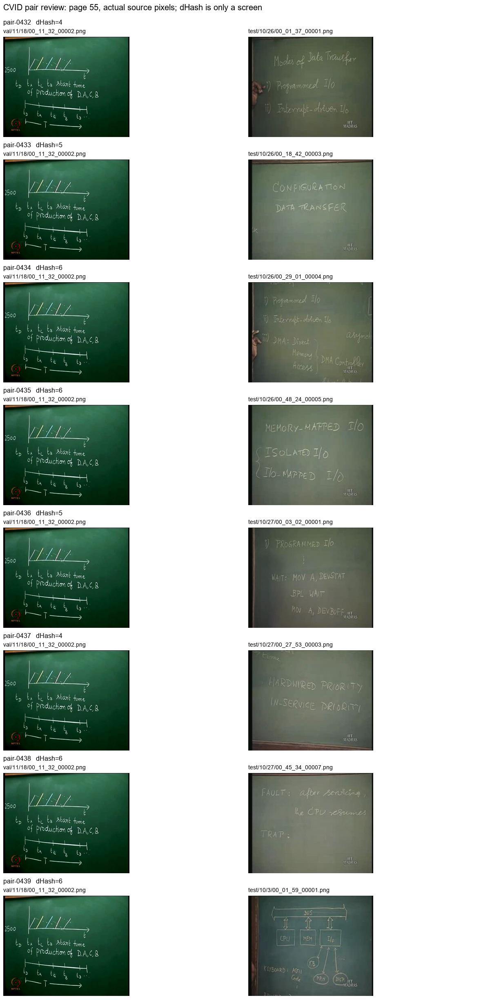

**pair-contact-sheets/page-056.jpg**

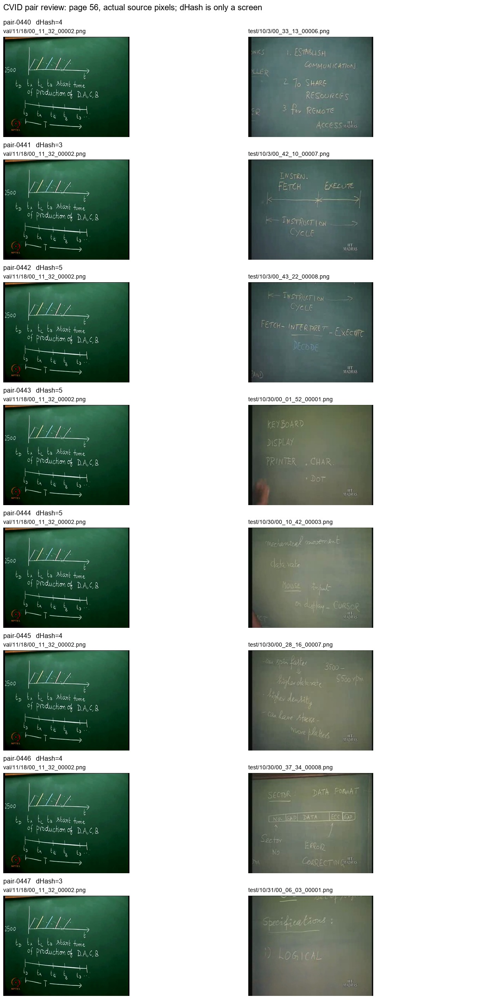

**pair-contact-sheets/page-057.jpg**

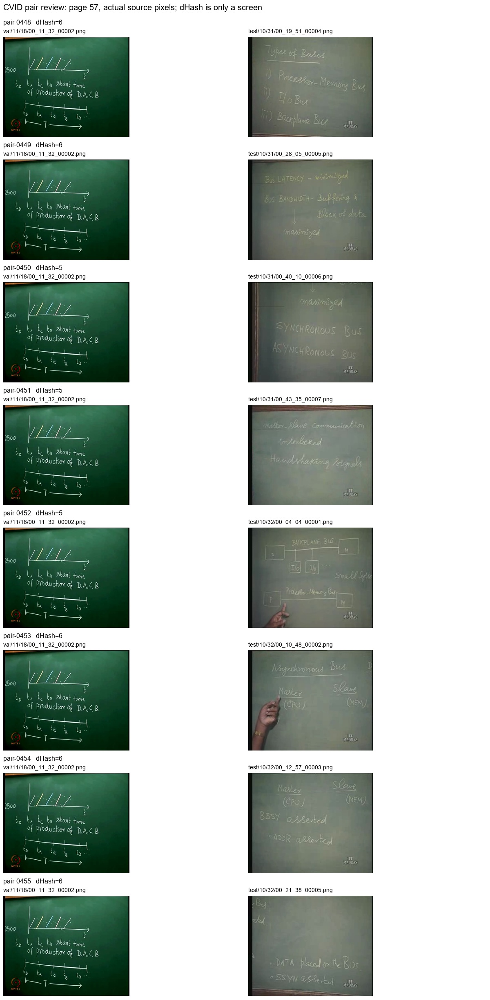

**pair-contact-sheets/page-058.jpg**

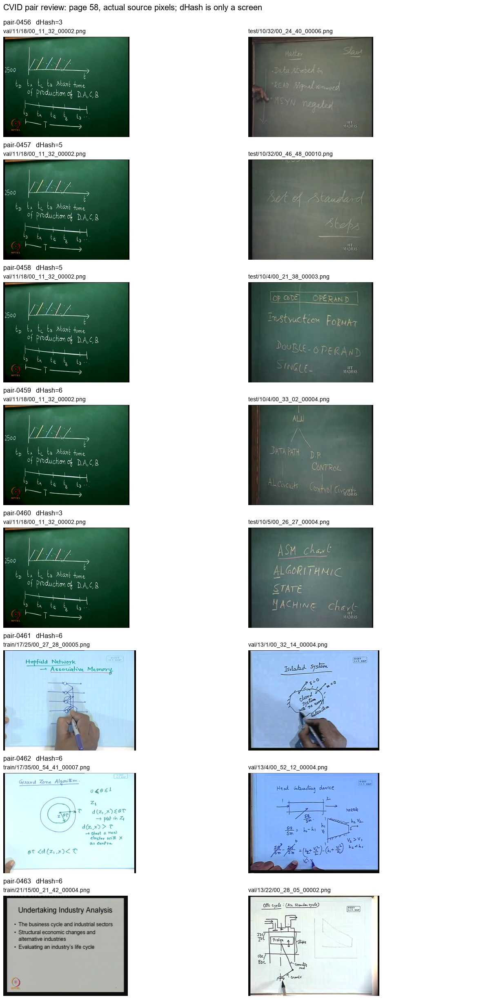

**pair-contact-sheets/page-059.jpg**

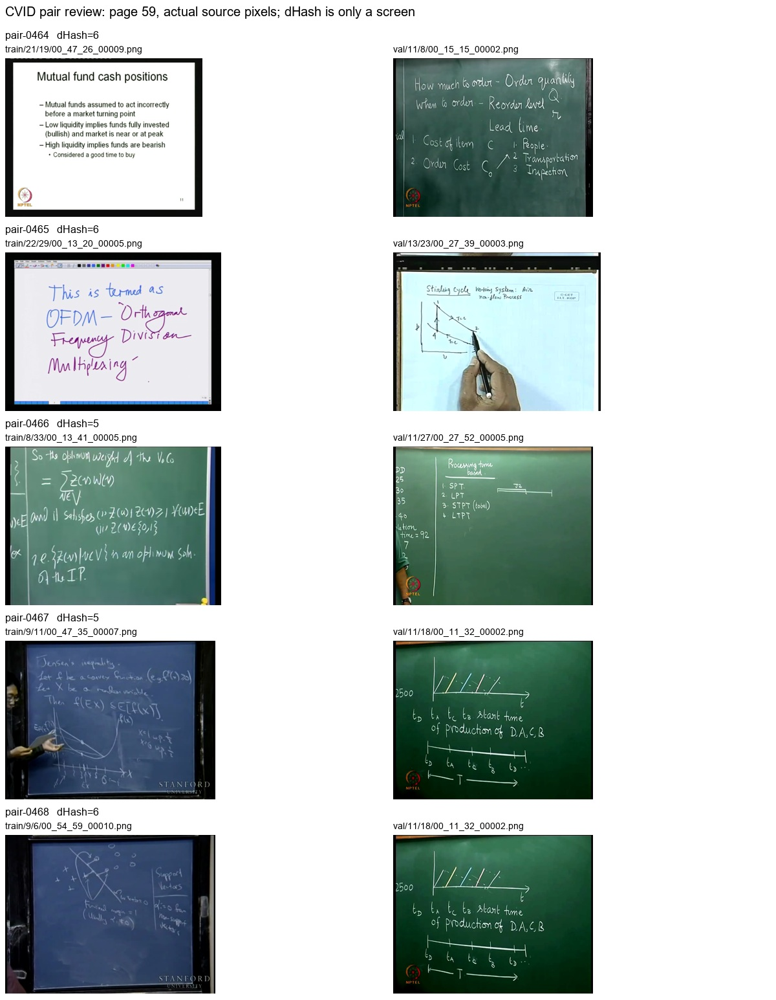

In [13]:
gallery('pair-contact-sheets')

## 7. Diagnostic semantic GT QC
Quy tắc chọn: 3 object mỗi khóa học, gần quantile 10/50/90% của box-height/frame-height, tie-break theo object ID, không thay thế mẫu. Review toàn bộ 72 crop và context bằng hai lượt Codex vision; không phải human gold hay mẫu ngẫu nhiên để ước lượng error rate toàn dataset.
`apparent_disagreement` và `uncertain` giữ nguyên GT, không tự tạo nhãn mới hoặc loại frame. Annotation recall không được chứng nhận: paper loại equations/symbols và các ví dụ cho thấy logo/interface được chọn không đồng nhất.

**all-72-semantic-reviews: 72 rows exported; 72 shown.**

sample_id,object_id,split,course,xml_text,decision,rationale,context_completeness
sem-000,train/1/1/00_17_09_00004.png#object-0035,train,1,new,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy
sem-001,train/1/1/00_13_50_00003.png#object-0006,train,1,version,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy
sem-002,train/1/1/00_00_50_00001.png#object-0002,train,1,integers,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy
sem-003,test/10/12/00_20_15_00003.png#object-0006,test,10,madras,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy
sem-004,test/10/1/00_13_09_00002.png#object-0005,test,10,e.g,uncertain,Visible e.g-like abbreviation has punctuation/parenthesis uncertainty; exact normalized string not certified.,not_certified; selective math/logo/interface annotation policy
sem-005,test/10/1/00_13_09_00002.png#object-0006,test,10,designed,uncertain,Visible DESIGN-like word suffix is covered by IIT MADRAS watermark; XML designed cannot be verified.,not_certified; selective math/logo/interface annotation policy
sem-006,val/11/1/00_19_55_00001.png#object-0004,val,11,on,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy
sem-007,val/11/1/00_19_55_00001.png#object-0001,val,11,26,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy
sem-008,val/11/10/00_04_36_00001.png#object-0019,val,11,rs,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy
sem-009,train/12/1/00_07_10_00002.png#object-0021,train,12,widom,visually_consistent_at_review_resolution,Visible crop is consistent with XML under declared normalization at this inspection resolution; not certified correct.,not_certified; selective math/logo/interface annotation policy


**semantic-review-counts: 9 rows exported; 9 shown.**

split,decision,sampled_objects
test,apparent_disagreement,1
test,uncertain,3
test,visually_consistent_at_review_resolution,17
train,apparent_disagreement,5
train,uncertain,1
train,visually_consistent_at_review_resolution,30
val,apparent_disagreement,1
val,uncertain,1
val,visually_consistent_at_review_resolution,13


**semantic-flags-requiring-gt-policy: 12 rows exported; 12 shown.**

sample_id,object_id,frame_id,split,course,xml_text,decision,rationale,context_completeness,reviewer,source_context_sha256,source_crop_sha256
sem-004,test/10/1/00_13_09_00002.png#object-0005,test/10/1/00_13_09_00002.png,test,10,e.g,uncertain,Visible e.g-like abbreviation has punctuation/parenthesis uncertainty; exact normalized string not certified.,not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,d86345450755a63c705bc3ab4fb44ea8f81c535d3ab70418e626bc26b5f2500b,3ae9d6e0d34c722b0a63ad5eaa1c8a1a86d4ae8e26776982604edbde24a9e686
sem-005,test/10/1/00_13_09_00002.png#object-0006,test/10/1/00_13_09_00002.png,test,10,designed,uncertain,Visible DESIGN-like word suffix is covered by IIT MADRAS watermark; XML designed cannot be verified.,not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,2d021b223e10fd4a6d83d9f43d546f5934ca872521408d5145074e43f432a424,633a4e8e4aaa072784d2c5ceee44d20bda044690f7fc515dfc74f559c7f834ed
sem-012,val/13/1/00_32_14_00004.png#object-0001,val/13/1/00_32_14_00004.png,val,13,ocet,uncertain,Small blurred institutional logo; exact raw letters of XML ocet not independently readable.,not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,d14e2a346b8ccabb73e154975437f8cb2349ad156b6de26bdc30300f010e9dbf,20cc1d29a32e5e56b931276603115b7e6bacf945bf0a49011b42c619782b55fa
sem-027,test/18/15/00_01_40_00001.png#object-0010,test/18/15/00_01_40_00001.png,test,18,kgp,uncertain,Small blurred logo; XML kgp plausible but exact letters not independently certified.,not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,ec6ee537c51c5fa36aa7d48da1500d6f12b983dbf883186da84014ad1942d2fa,ae1fc865cacd1962631633f6169a4518cce628381d292efcb56ee232693a0754
sem-034,val/2/11/00_04_59_00001.png#object-0001,val/2/11/00_04_59_00001.png,val,2,accost,apparent_disagreement,Crop visibly combines a drawn square checkbox and COST; XML accost is an artifact/boundary discrepancy; no replacement inferred.,not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,4a2fe55fb9065a0e80a3b7ce1495b12df4c22e9466ea1e19bbf8568463cf241b,843b7ebaf4b2fe4273f0690066a2f5ea4210f89660af1c40d9807c21fef13de6
sem-045,train/23/10/00_59_51_00011.png#object-0022,train/23/10/00_59_51_00011.png,train,23,homs,apparent_disagreement,"Visible handwritten homo. differs from XML homs; diagnostic flag, not an authorized correction.",not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,0d390c1c4e5c3ececf233ea803262bdaa6e5be5737069364b90d163d69250b51,d7902cf854ed1e8473252733510ae36369b7e1585e18ccaba6acc809c7c66298
sem-046,train/23/1/00_07_20_00001.png#object-0016,train/23/1/00_07_20_00001.png,train,23,eigenvalue,apparent_disagreement,Visible handwritten eigenvalues has plural suffix differing from XML eigenvalue.,not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,8aca2e83e2cc3b3dc338846175b868bbaefea626d7968027e215c666384a578c,eb9841afeccfe99eacffb6791b5630574694cc202b143c2dd78b7b307c24b83f
sem-054,train/4/1/00_45_17_00005.png#object-0008,train/4/1/00_45_17_00005.png,train,4,omega,apparent_disagreement,Visible word amazon differs from XML omega.,not_certified; selective math/logo/interface annotation policy,Codex root plus separate Codex reviewer; not independent human gold,e64cbcd624fb7418bb6bb3587e1471092529c03c44499196d5c4daba8ec500ea,6f73d3c9f9c5611b2d98830a479b1aa24f04607c14f19f4ec3455028a432ab7a
sem-055,train/4/10/00_10_53_00003.png#object-0001,train/4/10/00_10_53_00003.png,train,4,ka,uncertain,"Native context shows service key notation K_s, whereas XML 

**semantic-contact-sheets/page-001.jpg**

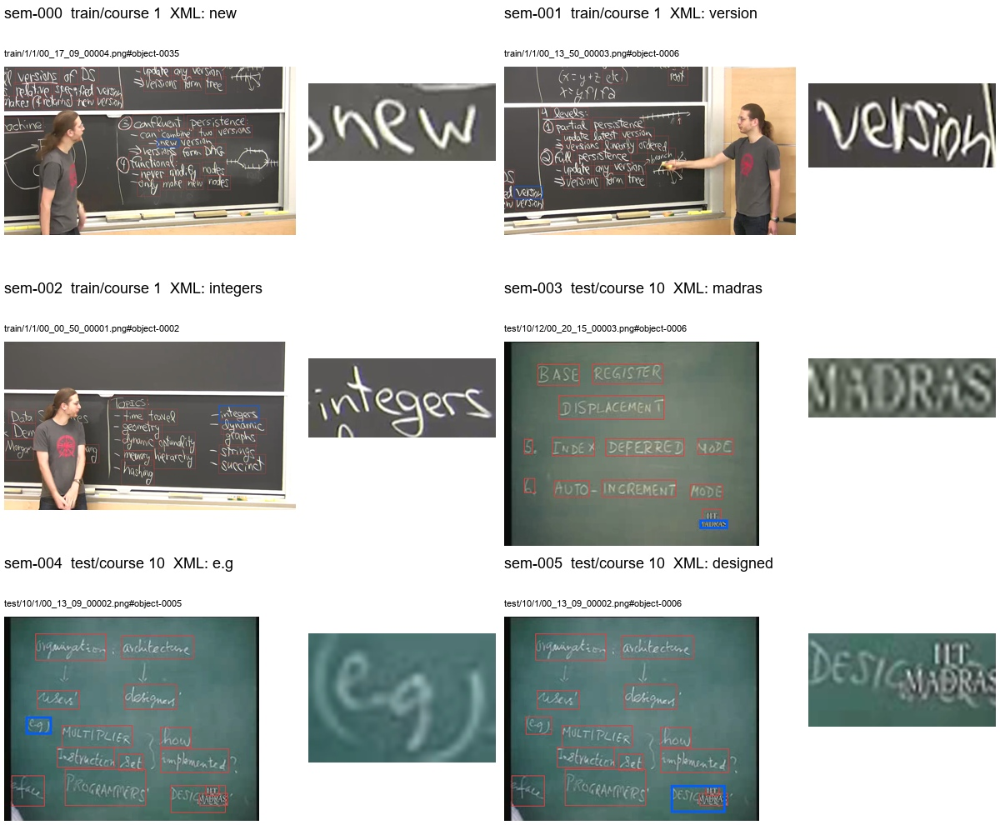

**semantic-contact-sheets/page-002.jpg**

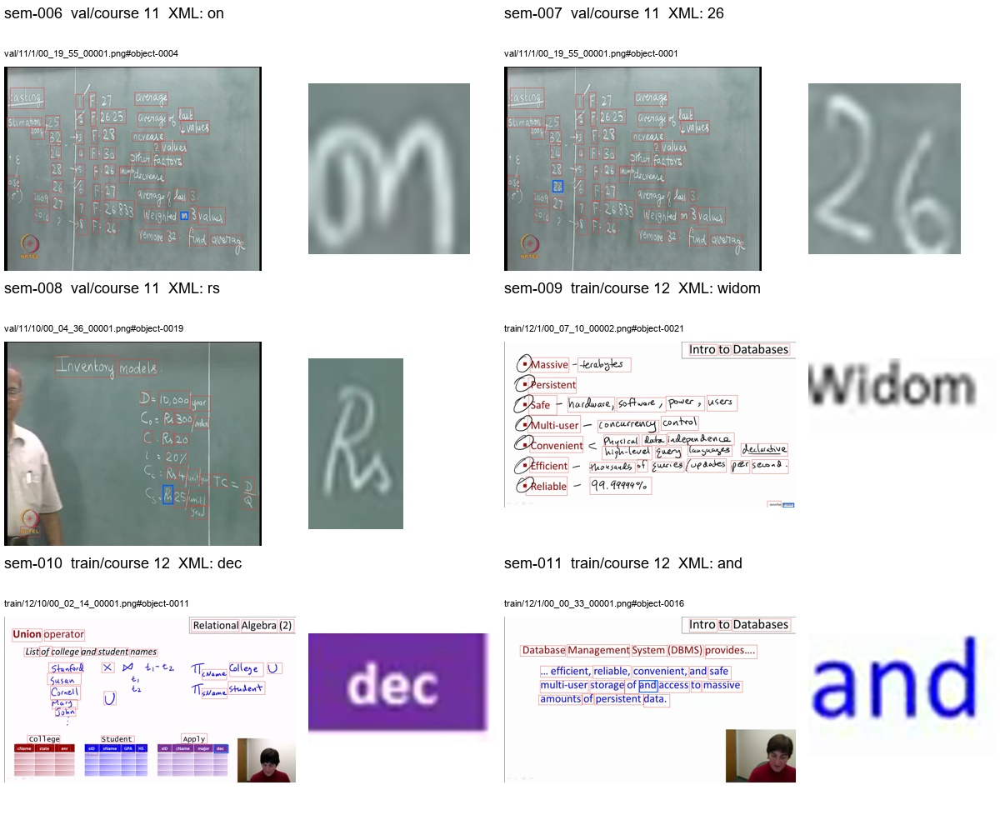

**semantic-contact-sheets/page-003.jpg**

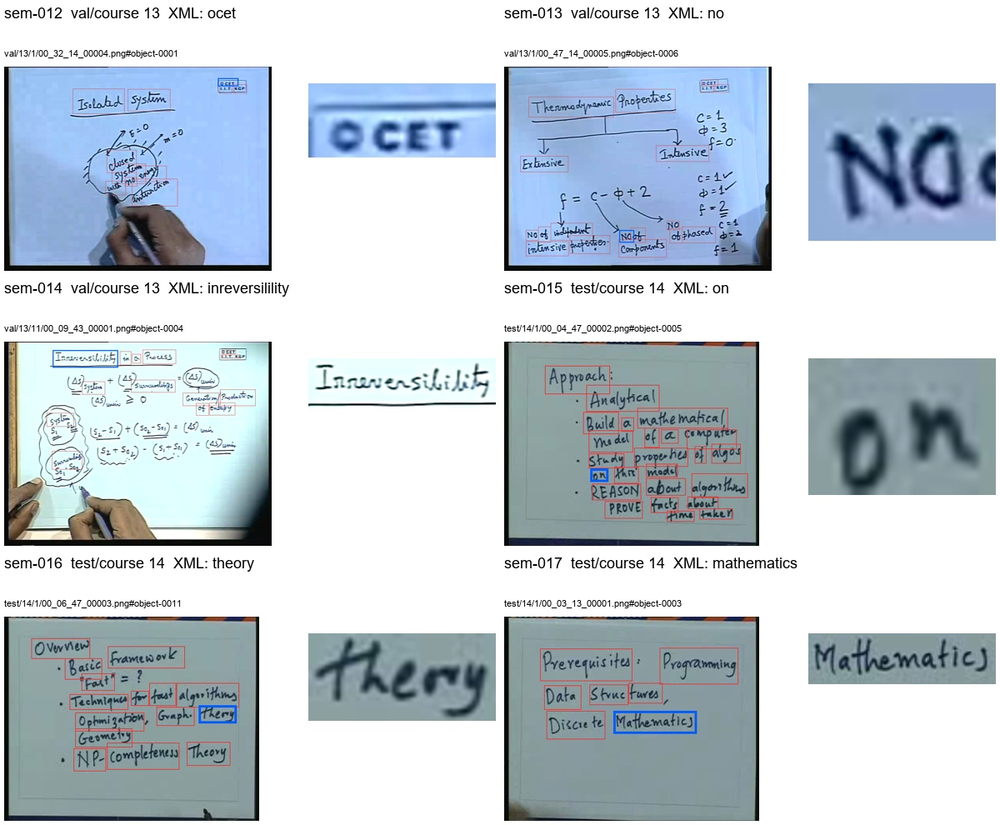

**semantic-contact-sheets/page-004.jpg**

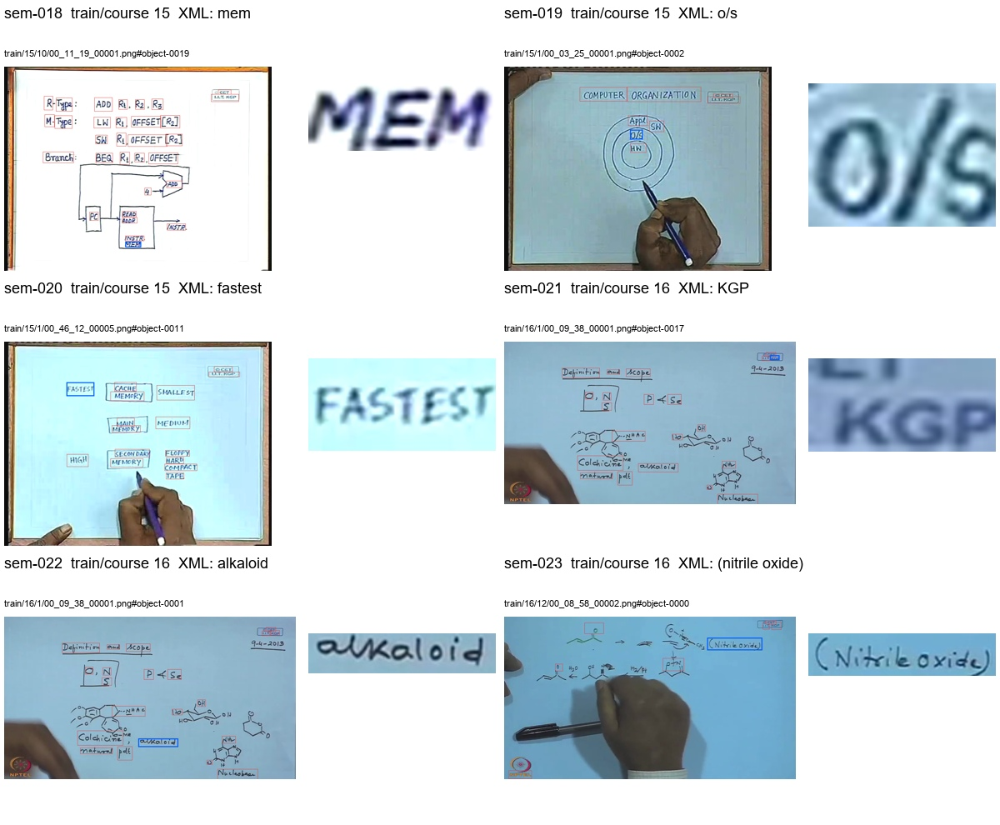

**semantic-contact-sheets/page-005.jpg**

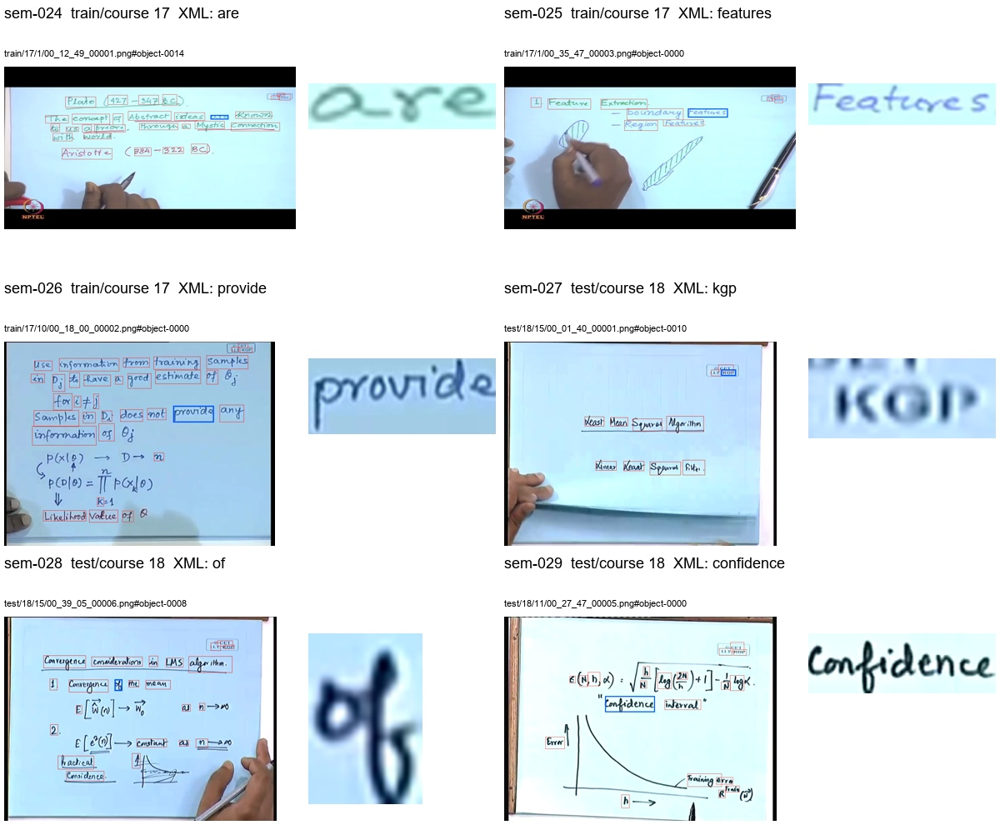

**semantic-contact-sheets/page-006.jpg**

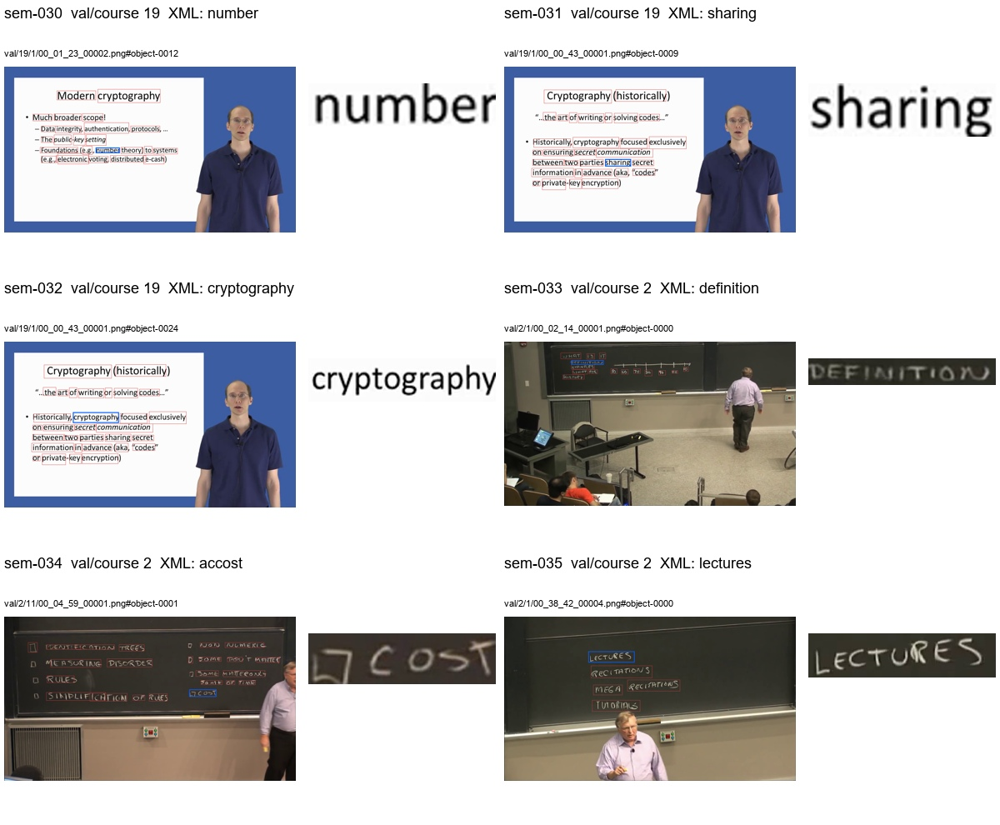

**semantic-contact-sheets/page-007.jpg**

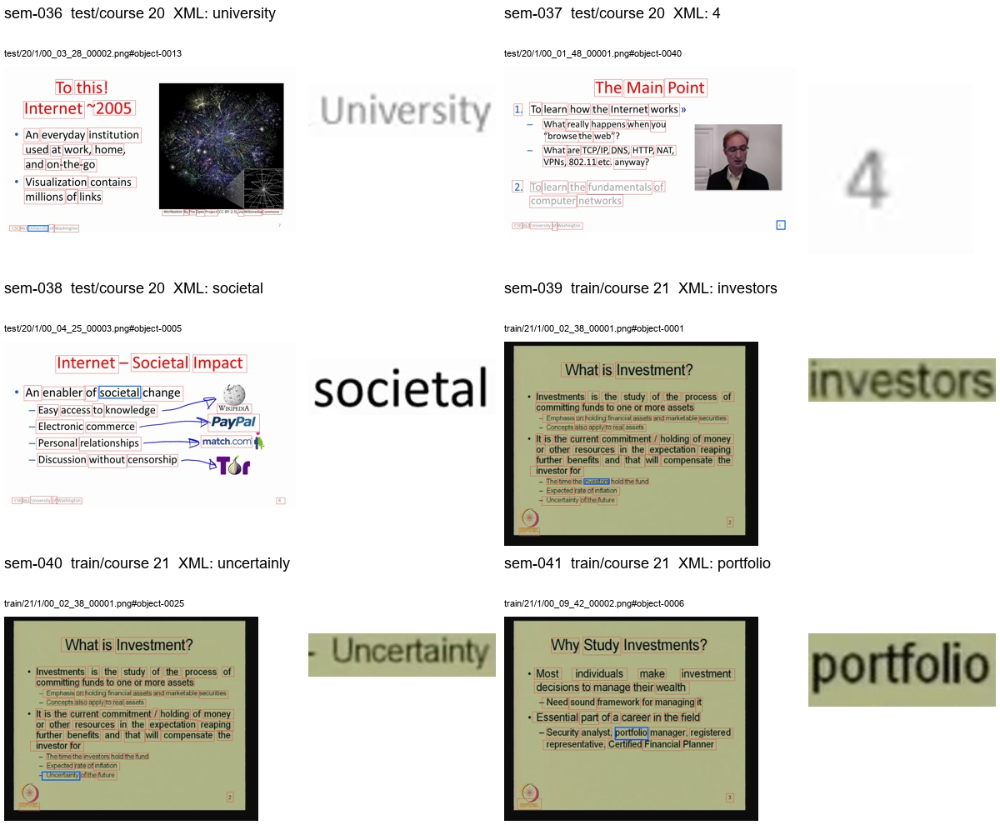

**semantic-contact-sheets/page-008.jpg**

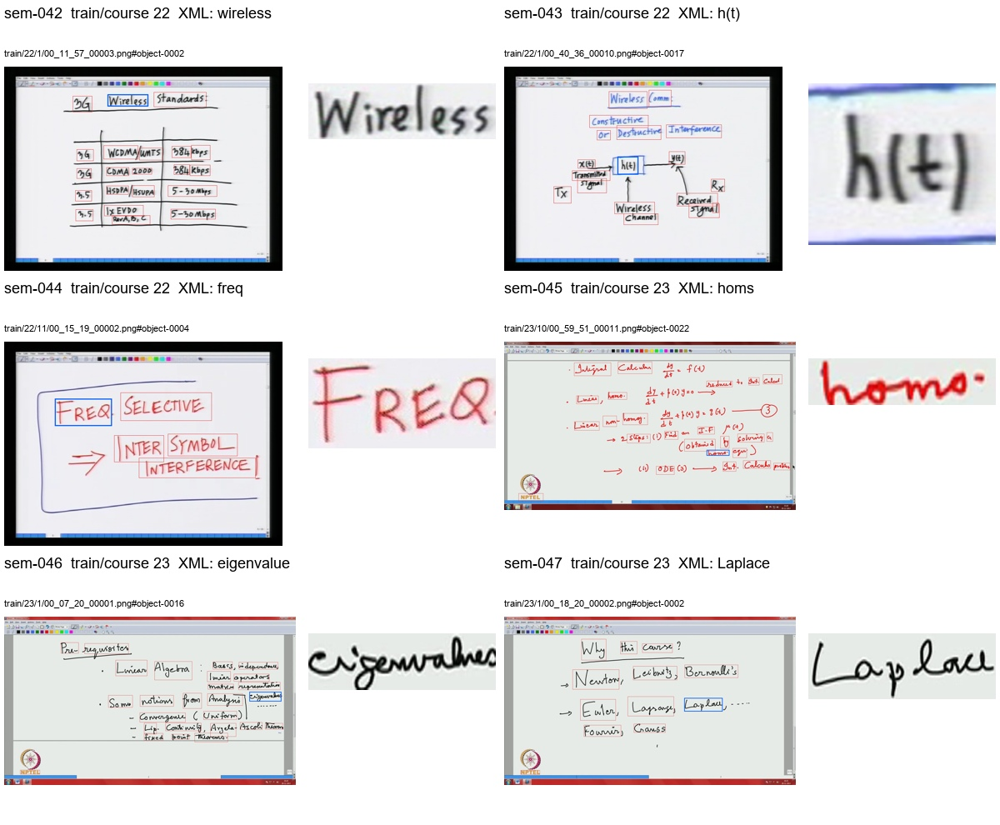

**semantic-contact-sheets/page-009.jpg**

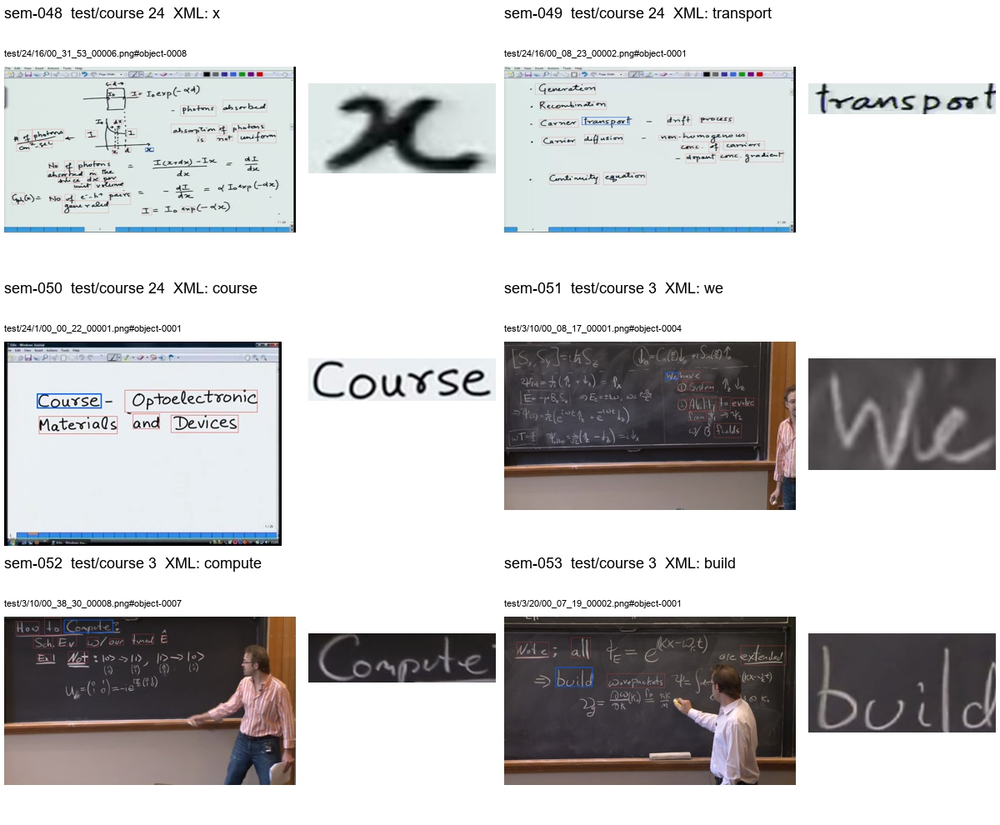

**semantic-contact-sheets/page-010.jpg**

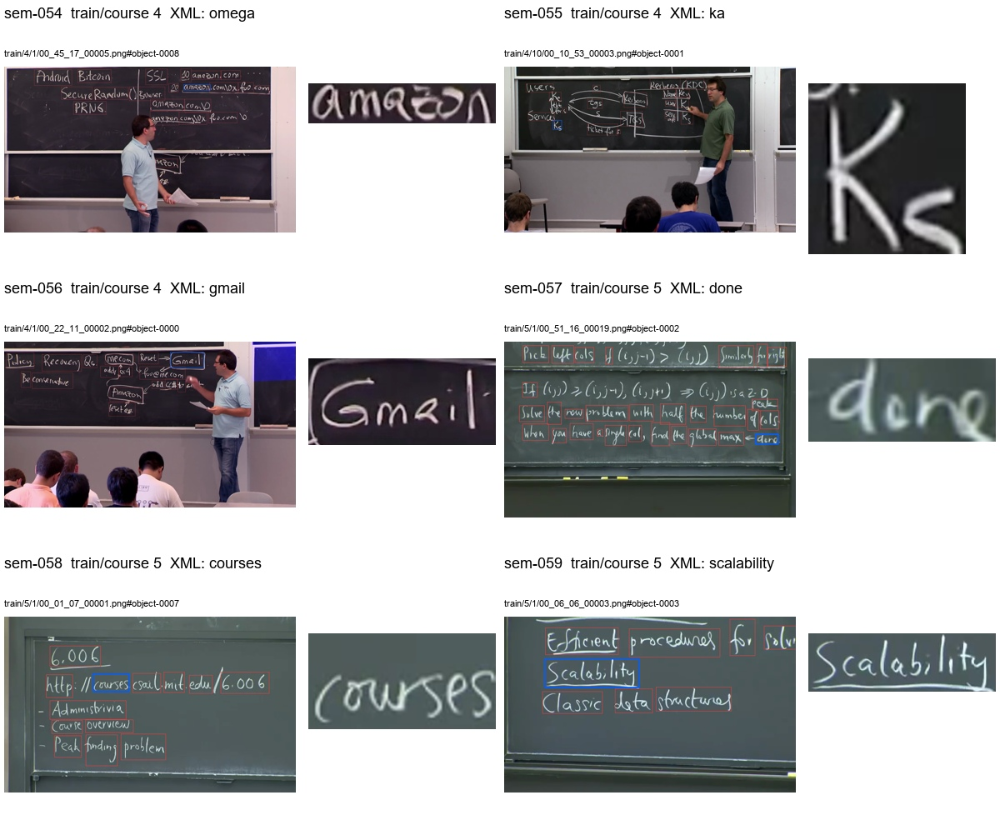

**semantic-contact-sheets/page-011.jpg**

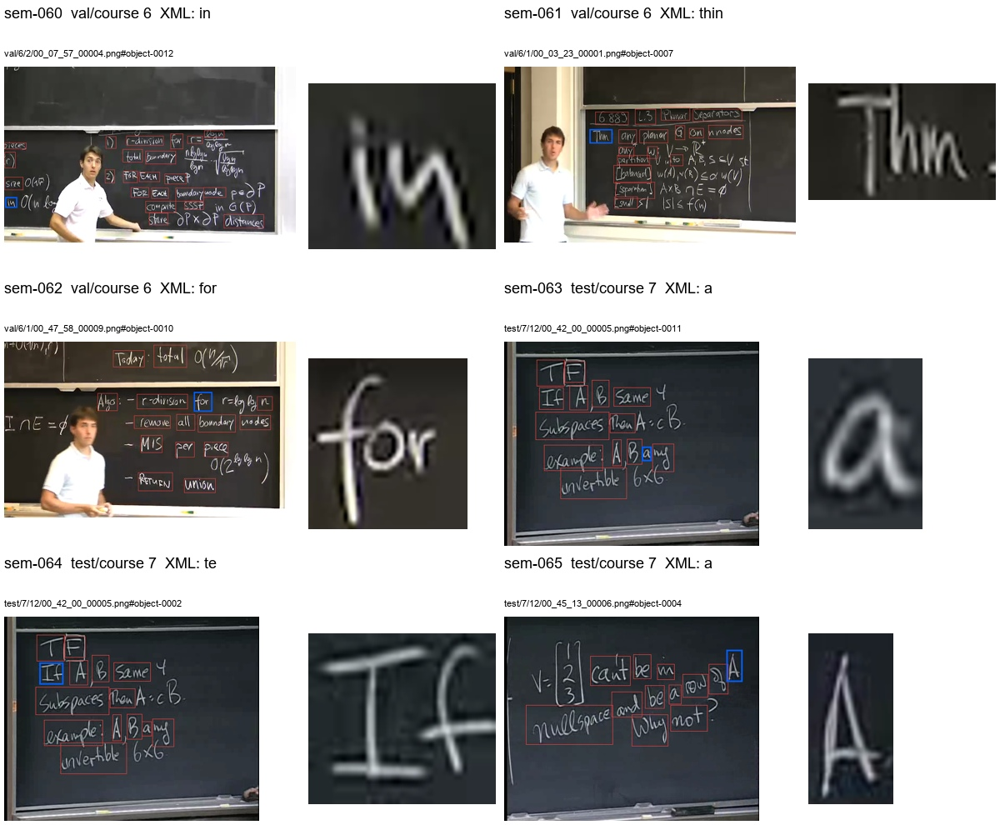

**semantic-contact-sheets/page-012.jpg**

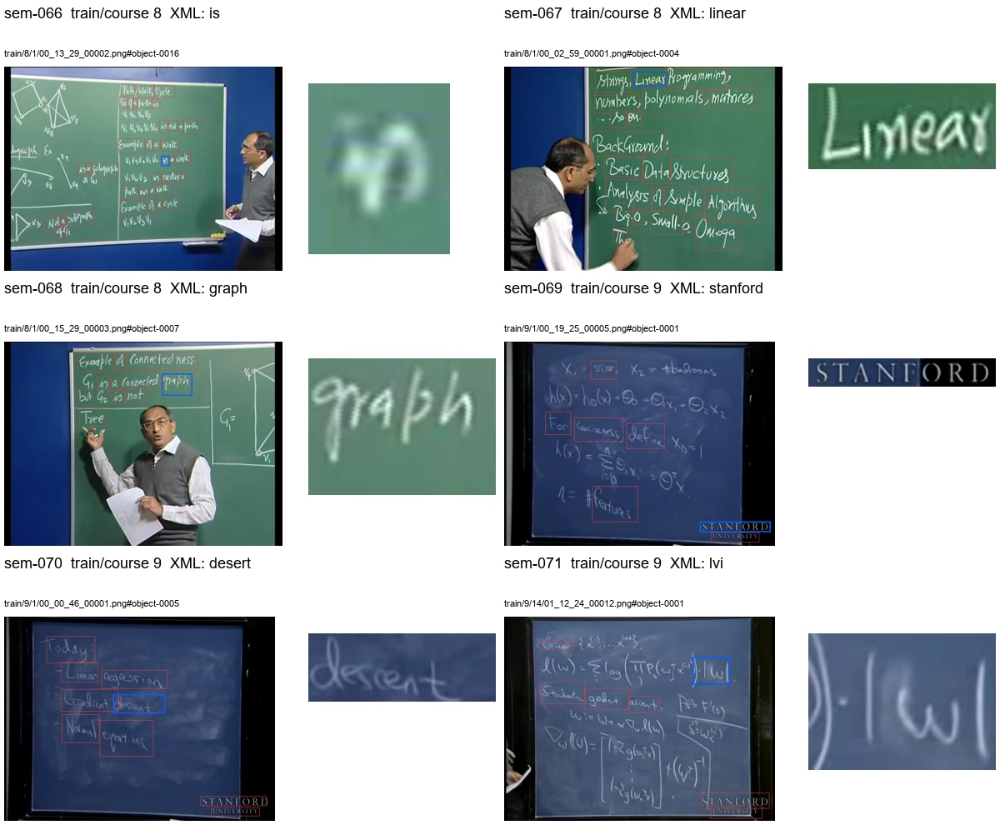

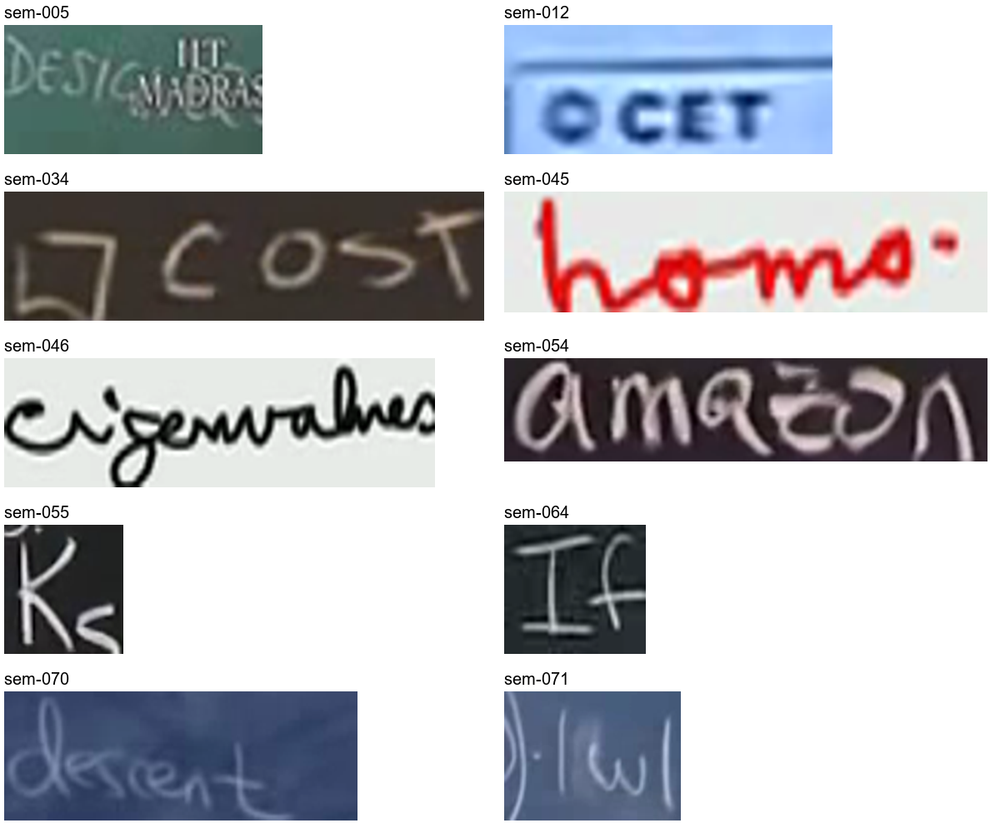

In [14]:
table(semantic[['sample_id','object_id','split','course','xml_text','decision','rationale','context_completeness']],'all-72-semantic-reviews')
table(semantic.groupby(['split','decision']).size().reset_index(name='sampled_objects'),'semantic-review-counts')
table(semantic[semantic.decision!='visually_consistent_at_review_resolution'],'semantic-flags-requiring-gt-policy')
gallery('semantic-contact-sheets')
display(Image(filename=str(OUT/'semantic-focused-review.png')))

## 8. Provenance, writer overlap và test exposure
Nguồn phương pháp: [paper tác giả, Section III và Table II](https://cdn.iiit.ac.in/cdn/cvit.iiit.ac.in/images/ConferencePapers/2018/localizing-recognizing-text.pdf).
Khóa học tách biệt không tự chứng minh người viết tách biệt. Tên file media không tự là source-video URL.
Các receipt lịch sử cho thấy test đã được đọc trong EDA; OCR comparison được kiểm tra có phạm vi validation crops. Chưa chứng minh mọi model run lịch sử đã được kiểm kê; EDA exposure không tự chứng minh test-based tuning.

In [15]:
videos = video_metadata()
assert len(videos)==811 and videos.complete_name.ne('').all()
table(videos,'all-811-video-metadata')
overlap = meta[meta.Instructor.str.contains('Erik Demaine',case=False,regex=False)]
table(overlap,'declared-instructor-overlap-train-val')
separation=[]
for a,b in itertools.combinations(SPLITS,2):
    separation.append(dict(left=a,right=b,shared_course_ids=len(set(f[f.split==a].course)&set(f[f.split==b].course)),
        shared_group_ids=len(set(f[f.split==a].source_group)&set(f[f.split==b].source_group))))
table(pd.DataFrame(separation),'release-identifier-separation')
display(Markdown('811 nhóm có local media filename; chưa có authenticated per-video mapping. Course URLs và metadata chỉ hỗ trợ course-level linkage. Erik Demaine được khai báo ở train/1, train/5, val/6. Không tuyên bố writer-disjoint.'))

**all-811-video-metadata: 811 rows exported; 811 shown.**

split,course,source_group,complete_name,http_urls,verified_per_video_source_url,source_mapping,metadata_member,metadata_sha256
test,10,10/1,01-Introduction to computing.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/1/metadata.txt,4c4844ad36204ac5b5e6a5f2e7f50c1872e1ae345ba4b30bc0732f67f5b4e855
test,10,10/10,10-controller design02.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/10/metadata.txt,acf723d84d5cbf52ce59b17bd0302bae528fa9a8bd379f05abfdb2cdf9a8c38b
test,10,10/11,11-typical micro instructions.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/11/metadata.txt,a2c2d297c87d7b0deef53fc8c7492e5745461205426dcd695cafae612c19c25e
test,10,10/12,12-Addressing Modes.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/12/metadata.txt,b388871791ba8eced7c4df180cec9727714ba5bfdd8e840331cce06727f05965
test,10,10/13,13-problem Exercise.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/13/metadata.txt,be658b1ead36337d401765433b90d2f13ec8ede8286a29d55b07b6ab71af4d0f
test,10,10/14,14-Problem exercise02.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/14/metadata.txt,eca93a2226b8bbd6c1f51ddb0a268997bd7f1e2f4645ef93452097ae4c10005e
test,10,10/15,15-Inroduction to memory system.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/15/metadata.txt,17d148890cfeb7de34bba01e8dc02f5dbd5f9602bd246e26dbbeebfa5a7407ed
test,10,10/16,16-CPU - Memory Interaction.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/16/metadata.txt,40269767d916f4ad70f1c970af331bf36f5c6fcdfee90f54dd24b4b5a3d48a96
test,10,10/17,17-Cache Organization.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/17/metadata.txt,6a67543a6559ff153e4e60a6b786707f5e65a6d967e6620c172a7f4e262bf80a
test,10,10/18,18-Cache Organization.flv,,,not_verified; local media filename only,IIIT-CVid/Frames/test/10/18/metadata.txt,fabbe525f3e11516f0abcfd8fc861262e22cf7e32f129d1b4bc74f67dc05836d


**declared-instructor-overlap-train-val: 3 rows exported; 3 shown.**

split,course,CourseName,Field,Instructor,Medium,Specialization,VideoURL
train,1,Advanced Data Structures,Engineering,Prof. Erik Demaine,Blackboard,Data Structures and Algorithms,https://www.youtube.com/watch?v=T0yzrZL1py0&list=PLUl4u3cNGP61hsJNdULdudlRL493b-XZf
train,5,Introduction to Algorithms,Engineering,Prof. Erik Demaine and Prof. Srinivas Devadas,Blackboard,Data Structures and Algorithms,https://www.youtube.com/watch?v=HtSuA80QTyo&list=PLUl4u3cNGP61Oq3tWYp6V_F-5jb5L2iHb&index=1
val,6,Algorithms for Planar Graphs and Beyond,Engineering,Prof. Erik Demaine,Blackboard,Algorithms and Data Structures,http://courses.csail.mit.edu/6.889/fall11/lectures/


**release-identifier-separation: 3 rows exported; 3 shown.**

left,right,shared_course_ids,shared_group_ids
train,val,0,0
train,test,0,0
val,test,0,0


811 nhóm có local media filename; chưa có authenticated per-video mapping. Course URLs và metadata chỉ hỗ trợ course-level linkage. Erik Demaine được khai báo ở train/1, train/5, val/6. Không tuyên bố writer-disjoint.

## 9. Kết luận, khả năng dùng test và artifacts
EDA kỹ thuật bao phủ toàn bộ dữ liệu và đã hoàn thành review hàng đợi/mẫu QC. Native test phù hợp để thiết kế endpoint course-held-out theo nhãn phát hành.
**Chưa khóa cohort test:** cần khai báo cách xử lý semantic flags và annotation scope; chưa xác minh độc lập video/người viết, lịch sử model test-use đầy đủ hay pretrained overlap. Không gộp train/val vào final test, không chọn thresholds/weights từ test observations.

In [16]:
summary = finish(receipt,pairs,semantic,snapshot)
print(json.dumps({k:v for k,v in summary.items() if k not in ('artifacts','code_sha256','existing_spotting_freeze_sha256')},indent=2,ensure_ascii=False))
export_rows = pd.DataFrame(summary['artifacts'])
display(HTML(export_rows[['path','sha256']].to_html(index=False,escape=True)))
print('Full CSV/GZIP ledgers:',OUT)
print('No source/spotting-freeze mutations; no OCR inference; no test cohort freeze.')

{
  "schema": "cvid_all_split_eda_v1",
  "source_archive_sha256": "b5b562580e250ee3336462b7699bc79d0d1149d3b8cc82f1b221a0d0ce4fb489",
  "coverage": {
    "frames": 5475,
    "objects": 137745,
    "decoded_crops": 137745,
    "indexed_crops": 137745,
    "read_failures": 0,
    "unmatched_objects": 0
  },
  "crop_correspondence": {
    "unique": 137641,
    "equivalent_ambiguous": 104
  },
  "raw_crop_xml_label_differences": 238,
  "visual_pair_review": {
    "count": 469,
    "decisions": {
      "different_observed_content": 469
    },
    "reviewer": "single Codex visual review; queue-limited"
  },
  "semantic_review": {
    "samples": 72,
    "decisions": {
      "visually_consistent_at_review_resolution": 60,
      "apparent_disagreement": 7,
      "uncertain": 5
    },
    "limit": "course/height diagnostic sample; two Codex reviewers, not independent human gold; no population error rate"
  },
  "readiness": {
    "eda_execution_complete": true,
    "descriptive_released_label_pr

path,sha256
experiments/outputs/cvid-all-split-eda-261014/frames.csv.gz,acbf04e6eeddf9a32f144f7e825b5ace5a12e2b358c6dbc3eeaad76d40b50d28
experiments/outputs/cvid-all-split-eda-261014/objects.csv.gz,aa3772d49498d100426a42390372598666f3b853e3760f56f9784911877eff95
experiments/outputs/cvid-all-split-eda-261014/crops.csv.gz,6f65cbbcf00db52773073f449fb6b231c5869d61b7b8564ef0ff735e046b2427
experiments/outputs/cvid-all-split-eda-261014/courses.csv,24420324f4c0563fb00edf11304ede07a8f3197d867d8a41b0ae5f7eec4ed652
experiments/outputs/cvid-all-split-eda-261014/read-failures.csv,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
experiments/outputs/cvid-all-split-eda-261014/unmatched-objects.csv,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
experiments/outputs/cvid-all-split-eda-261014/tables/split-accounting.csv,b4b3a9e99a52c89c92fb007eb974ceca19bb91a67cf73f3c8117800cafe36f59
experiments/outputs/cvid-all-split-eda-261014/figures/01-accounting.png,d681278fe157b9e315e3e32806d598dbb26e2e6b3ece7aee86ec7d2ef1052b5a
experiments/outputs/cvid-all-split-eda-261014/figures/01-accounting.svg,15f51ab64932a026caf9583ace42d7bfc116345f44a606be282f517f45bcd003
experiments/outputs/cvid-all-split-eda-261014/tables/all-course-metadata.csv,24420324f4c0563fb00edf11304ede07a8f3197d867d8a41b0ae5f7eec4ed652


Full CSV/GZIP ledgers: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\cvid-all-split-eda-261014
No source/spotting-freeze mutations; no OCR inference; no test cohort freeze.
